# Survival Analysis: Worcester Heart Attack Study (WHAS500)

**Dataset:** WHAS500 — 500 patients hospitalized for acute myocardial infarction (heart attack)
**Objective:** Model time-to-death and identify clinical risk factors using multiple survival analysis frameworks
**Methods:** Kaplan-Meier Estimation, Cox Proportional Hazards, Accelerated Failure Time (Weibull), Random Survival Forest, Model Comparison

---

## 1. Environment Setup & Data Loading

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from lifelines import KaplanMeierFitter, CoxPHFitter, WeibullAFTFitter
from lifelines import LogNormalAFTFitter, LogLogisticAFTFitter
from lifelines.statistics import logrank_test, multivariate_logrank_test, proportional_hazard_test
from lifelines.utils import concordance_index as lifelines_ci

from sklearn.model_selection import KFold
from sklearn.inspection import permutation_importance

# Random Survival Forest and survival metrics (pip install scikit-survival)
from sksurv.ensemble import RandomSurvivalForest
from sksurv.metrics import integrated_brier_score
from sksurv.util import Surv

sns.set_theme(style='whitegrid', context='notebook', font_scale=1.1)
plt.rcParams.update({
    'figure.dpi': 120, 'savefig.dpi': 150,
    'axes.titlesize': 13, 'axes.labelsize': 11,
    'figure.figsize': (10, 6)
})

print("All libraries loaded successfully.")

All libraries loaded successfully.


### 1.1 Load WHAS500 Dataset

In [2]:
df = pd.read_csv('whas500.csv')

print(f"Dataset shape: {df.shape}")
print(f"\nOutcome summary:")
print(f"  Deaths:   {df['event'].sum()} ({df['event'].mean()*100:.1f}%)")
print(f"  Censored: {(1-df['event']).sum()} ({(1-df['event']).mean()*100:.1f}%)")
print(f"  Follow-up: {df['time'].min():.0f} – {df['time'].max():.0f} days "
      f"(median {df['time'].median():.0f})")
print(f"\nFirst 5 rows:")
df.head()

Dataset shape: (500, 16)

Outcome summary:
  Deaths:   215 (43.0%)
  Censored: 285 (57.0%)
  Follow-up: 1 – 2358 days (median 632)

First 5 rows:


,afb,age,av3,bmi,chf,cvd,diasbp,gender,hr,los,miord,mitype,sho,sysbp,time,event
0,1,83.0,0,25.54051,0,1,78.0,0,89.0,5.0,1,0,0,152.0,2178.0,0
1,0,49.0,0,24.02398,0,1,60.0,0,84.0,5.0,0,1,0,120.0,2172.0,0
2,0,70.0,0,22.14290,0,0,88.0,1,83.0,5.0,0,1,0,147.0,2190.0,0
3,0,70.0,0,26.63187,1,1,76.0,0,65.0,10.0,0,1,0,123.0,297.0,1
4,0,70.0,0,24.41255,0,1,85.0,0,63.0,6.0,0,1,0,135.0,2131.0,0


### 1.2 Variable Dictionary

| Variable | Description | Type |
|----------|-------------|------|
| `afb` | Atrial fibrillation (0 = No, 1 = Yes) | Binary |
| `age` | Age at admission (years) | Continuous |
| `av3` | Complete heart block (0 = No, 1 = Yes) | Binary |
| `bmi` | Body mass index (kg/m²) | Continuous |
| `chf` | Congestive heart failure (0 = No, 1 = Yes) | Binary |
| `cvd` | History of cardiovascular disease (0 = No, 1 = Yes) | Binary |
| `diasbp` | Diastolic blood pressure (mmHg) | Continuous |
| `gender` | Sex (0 = Male, 1 = Female) | Binary |
| `hr` | Initial heart rate (bpm) | Continuous |
| `los` | Length of hospital stay (days) | Continuous |
| `miord` | MI order (0 = First, 1 = Recurrent) | Binary |
| `mitype` | MI type (0 = Non-Q-wave, 1 = Q-wave) | Binary |
| `sho` | Cardiogenic shock (0 = No, 1 = Yes) | Binary |
| `sysbp` | Systolic blood pressure (mmHg) | Continuous |
| `time` | Follow-up time in days (`lenfol`) | **Outcome** |
| `event` | Death indicator (`fstat`; 1 = Dead) | **Outcome** |

## 2. Exploratory Data Analysis

### 2.1 Descriptive Statistics

In [3]:
continuous = ['age', 'bmi', 'diasbp', 'hr', 'los', 'sysbp']
binary = ['afb', 'av3', 'chf', 'cvd', 'gender', 'miord', 'mitype', 'sho']

print("=== Continuous Variables ===")
display(df[continuous].describe().round(2))

print("\n=== Binary Variables (prevalence) ===")
prev = df[binary].mean().round(3).to_frame('prevalence')
prev['n'] = df[binary].sum().astype(int)
display(prev)

# Values that are physiologically implausible or unusual. They are kept as published in
# WHAS500 (they cannot be verified), and a sensitivity check in Section 4.5 confirms
# they do not drive the results.
print("\n=== Data-Quality Flags ===")
quality_flags = {
    'diasbp < 20 mmHg': df['diasbp'] < 20,
    'bmi < 15 kg/m²': df['bmi'] < 15,
    'los = 0 days': df['los'] == 0,
}
for label, m in quality_flags.items():
    print(f"  {label:<18} n = {m.sum()}")

=== Continuous Variables ===


,age,bmi,diasbp,hr,los,sysbp
count,500.00,500.00,500.00,500.00,500.00,500.00
mean,69.85,26.61,78.27,87.02,6.12,144.70
std,14.49,5.41,21.55,23.59,4.71,32.29
min,30.00,13.05,6.00,35.00,0.00,57.00
25%,59.00,23.22,63.00,69.00,3.00,123.00
50%,72.00,25.95,79.00,85.00,5.00,141.50
75%,82.00,29.39,91.25,100.25,7.00,164.00
max,104.00,44.84,198.00,186.00,47.00,244.00



=== Binary Variables (prevalence) ===


,prevalence,n
afb,0.156,78
av3,0.022,11
chf,0.310,155
cvd,0.750,375
gender,0.400,200
miord,0.342,171
mitype,0.306,153
sho,0.044,22



=== Data-Quality Flags ===
  diasbp < 20 mmHg   n = 2
  bmi < 15 kg/m²     n = 4
  los = 0 days       n = 3


### 2.2 Distribution of Continuous Variables

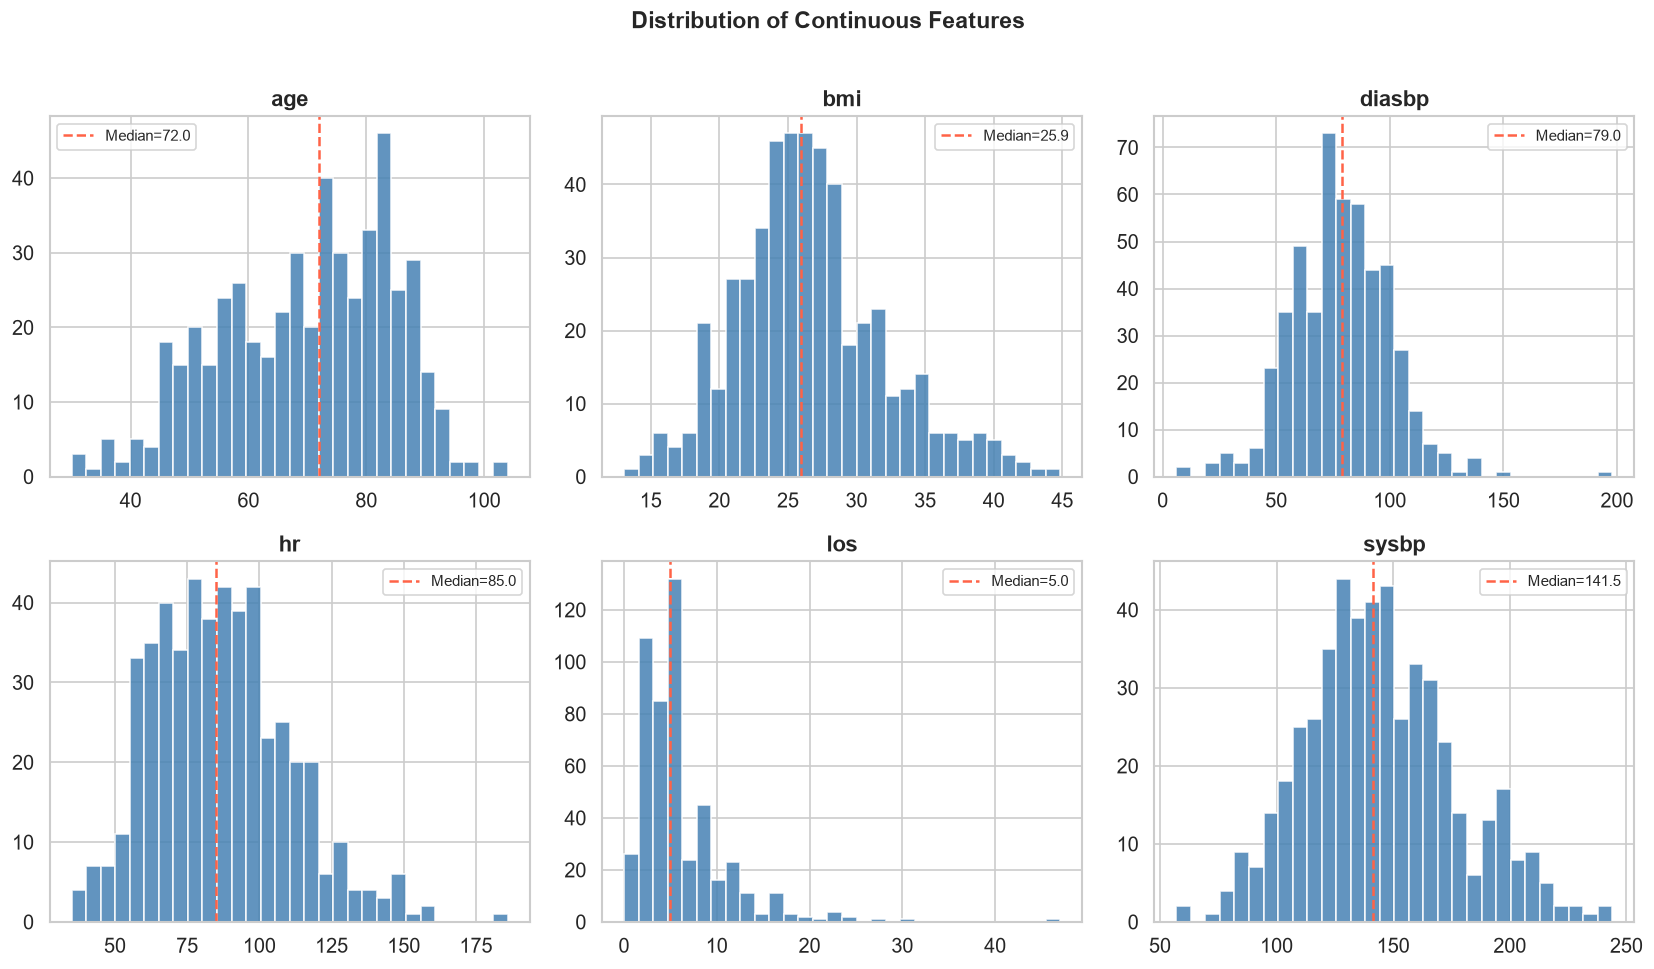

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, col in zip(axes.ravel(), continuous):
    ax.hist(df[col], bins=30, edgecolor='white', alpha=0.85, color='steelblue')
    ax.axvline(df[col].median(), color='tomato', ls='--', lw=1.5,
               label=f'Median={df[col].median():.1f}')
    ax.set_title(col, fontweight='bold')
    ax.legend(fontsize=9)
plt.suptitle('Distribution of Continuous Features', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

### 2.3 Outcome by Clinical Features

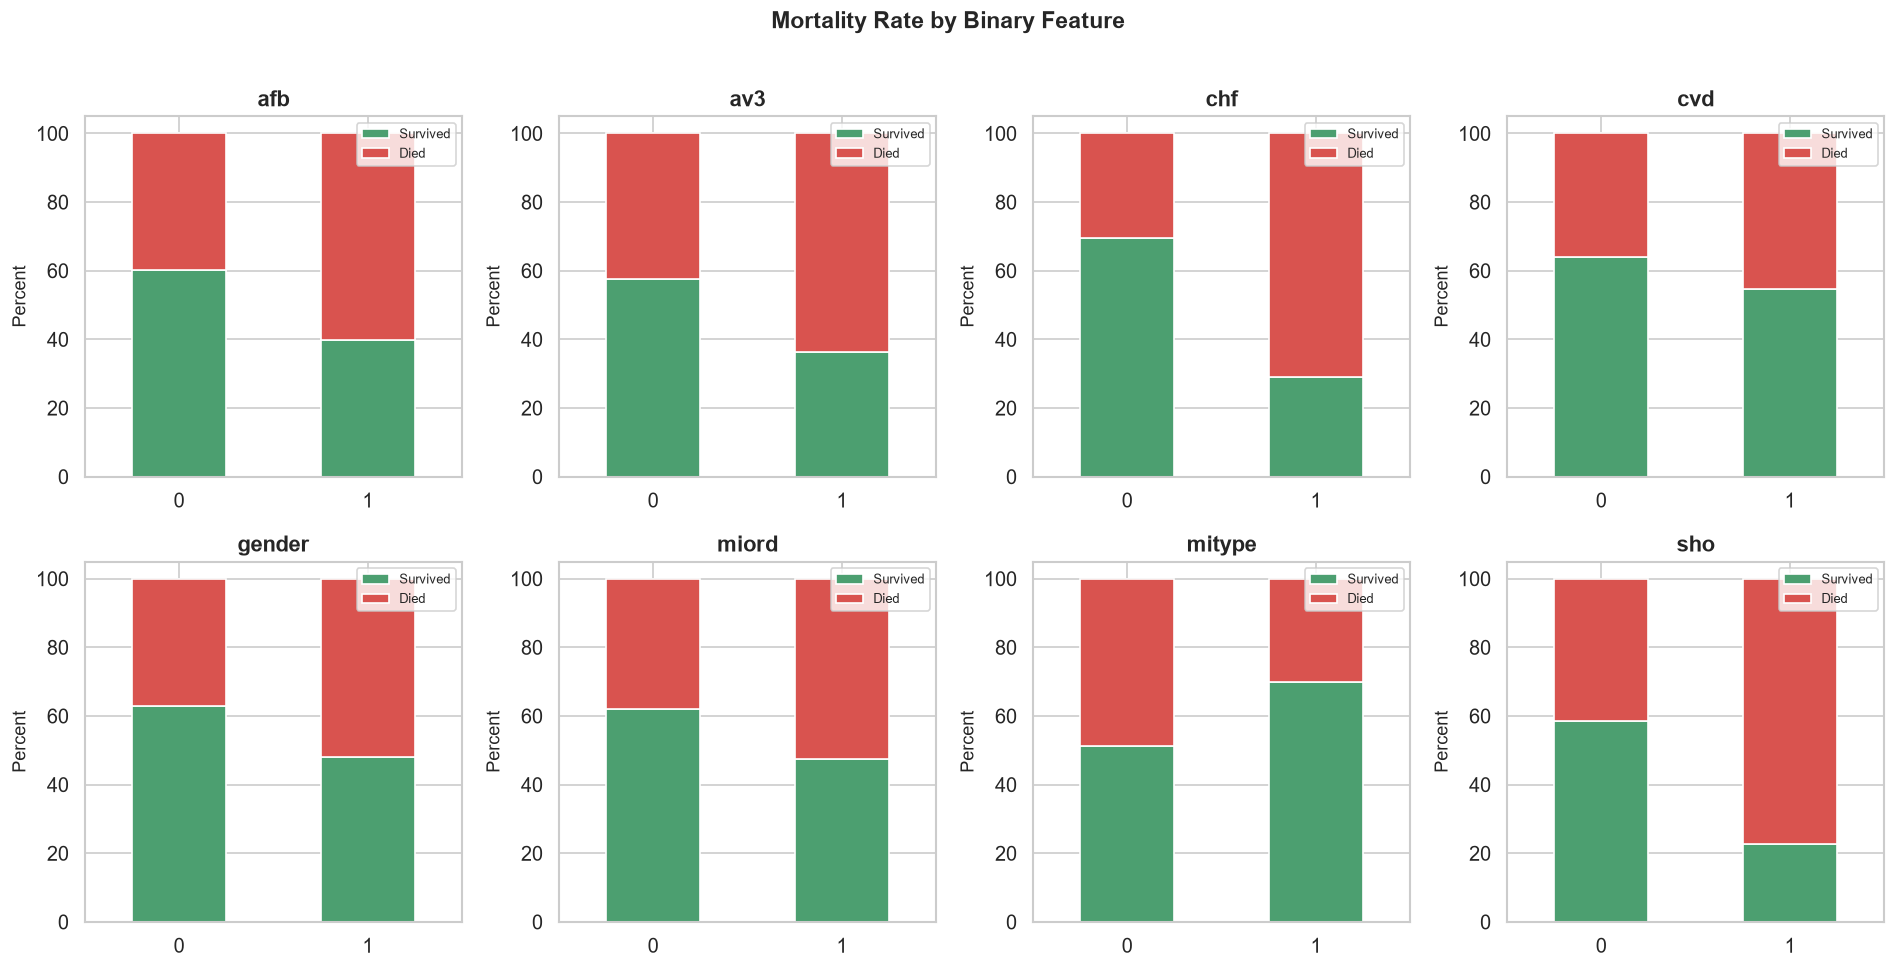

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, col in zip(axes.ravel(), binary):
    ct = pd.crosstab(df[col], df['event'], normalize='index') * 100
    ct.plot.bar(stacked=True, ax=ax, color=['#4c9f70', '#d9534f'], edgecolor='white')
    ax.set_title(col, fontweight='bold')
    ax.set_ylabel('Percent')
    ax.set_xlabel('')
    ax.legend(['Survived', 'Died'], fontsize=8)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
plt.suptitle('Mortality Rate by Binary Feature', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

### 2.4 Continuous Variables by Outcome

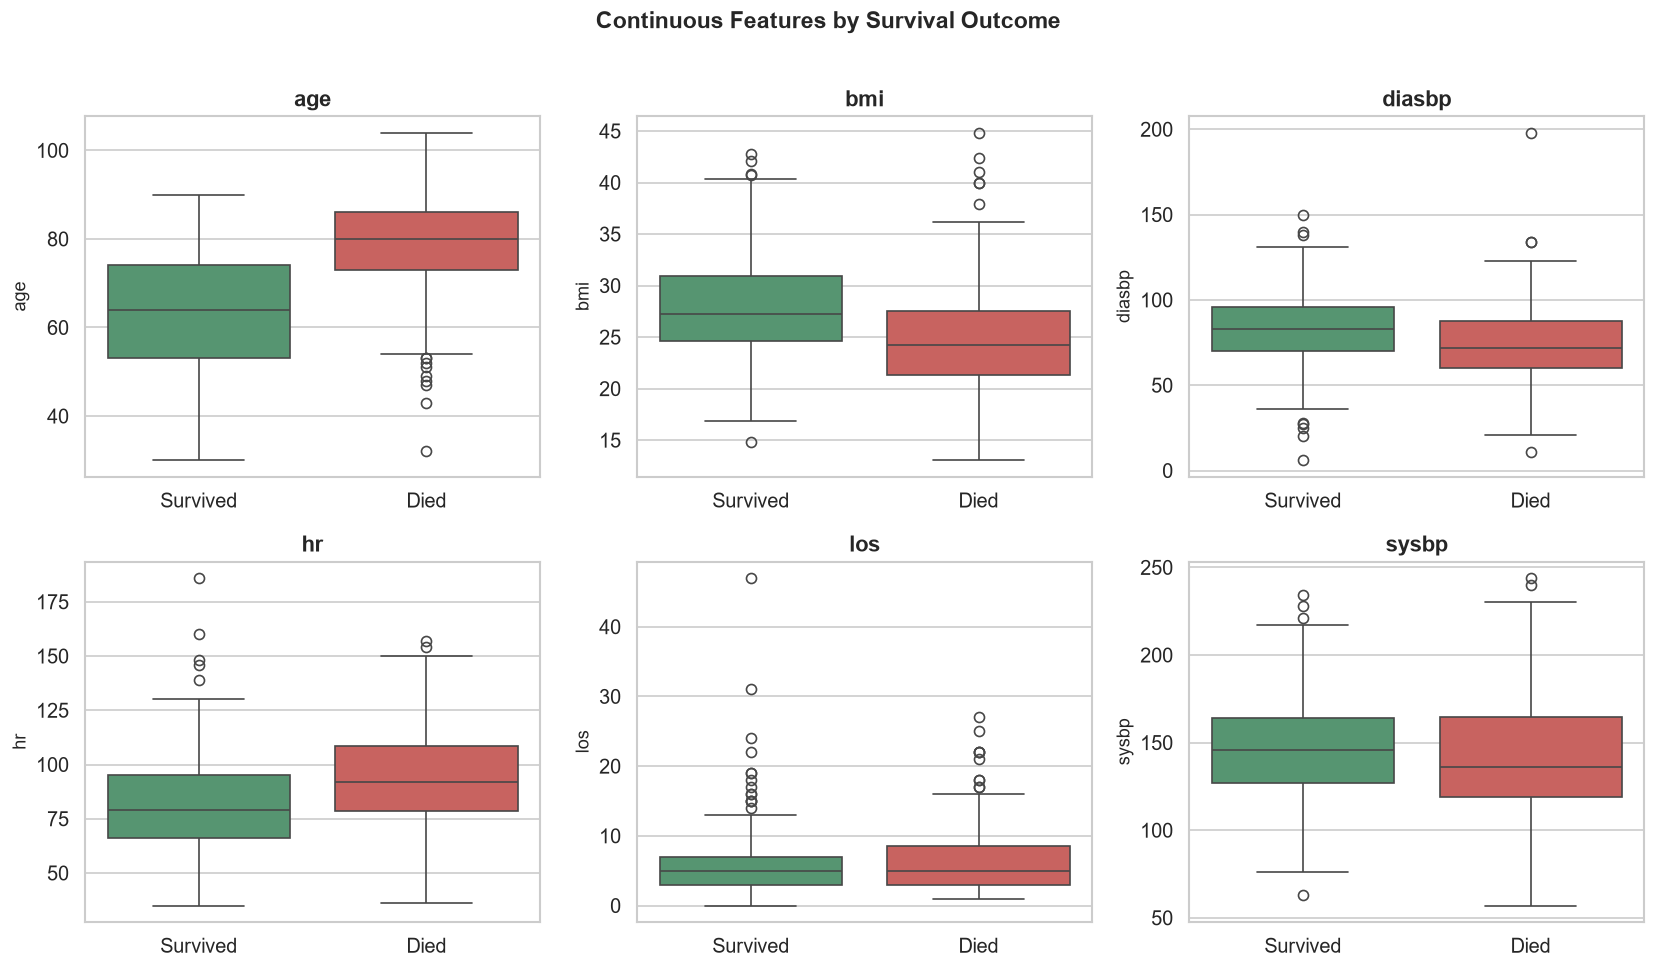

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, col in zip(axes.ravel(), continuous):
    sns.boxplot(data=df, x='event', y=col, ax=ax, palette=['#4c9f70', '#d9534f'],
                hue='event', legend=False)
    ax.set_xticklabels(['Survived', 'Died'])
    ax.set_xlabel('')
    ax.set_title(col, fontweight='bold')
plt.suptitle('Continuous Features by Survival Outcome', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

### 2.5 Correlation Heatmap

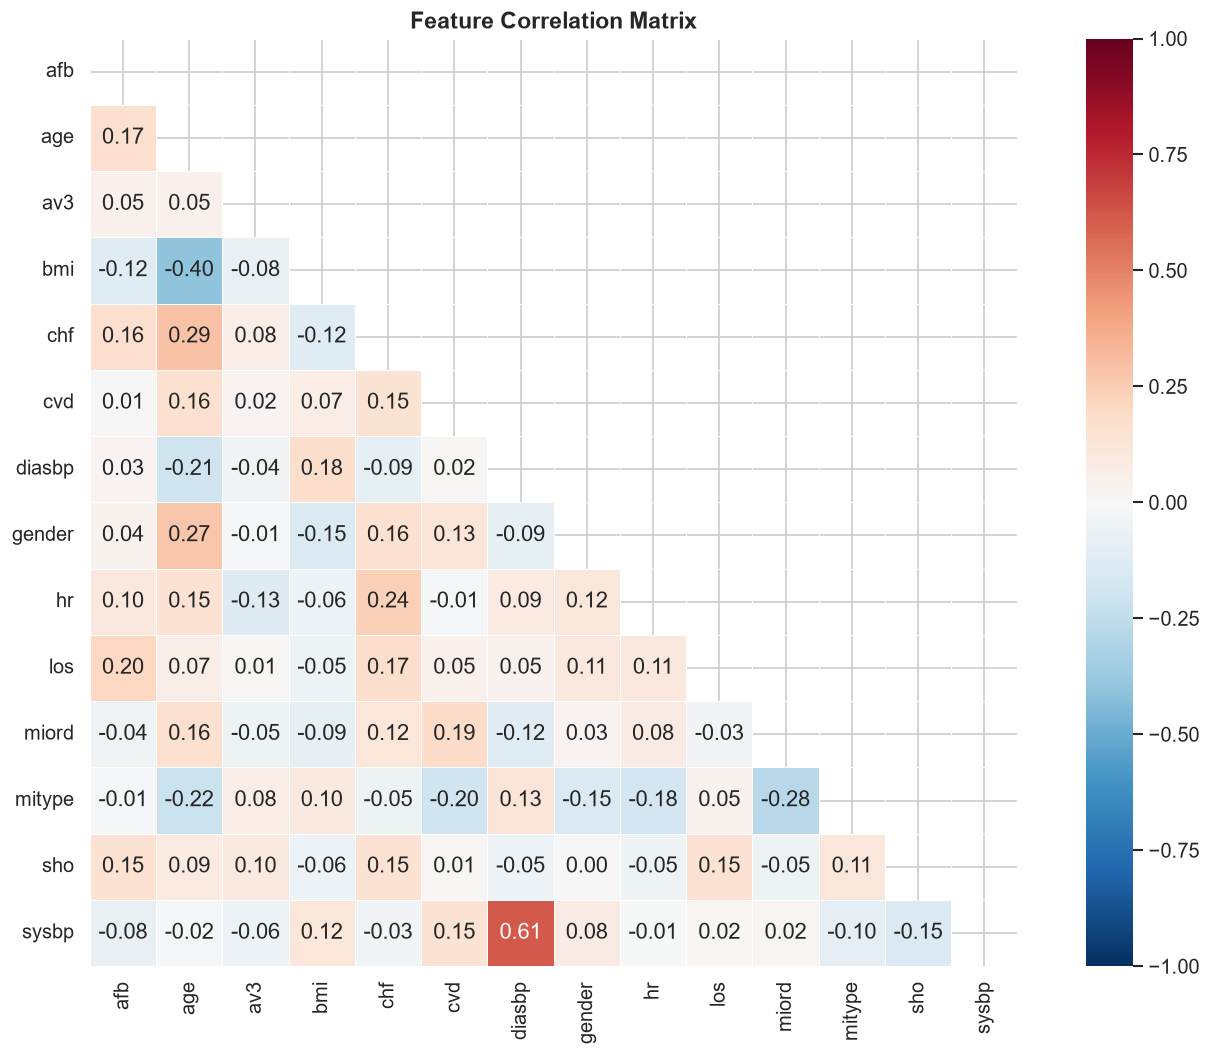

In [7]:
fig, ax = plt.subplots(figsize=(12, 9))
corr = df.drop(columns=['time', 'event']).corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, vmin=-1, vmax=1, square=True, linewidths=0.5, ax=ax)
ax.set_title('Feature Correlation Matrix', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### 2.6 Follow-up Time Distribution

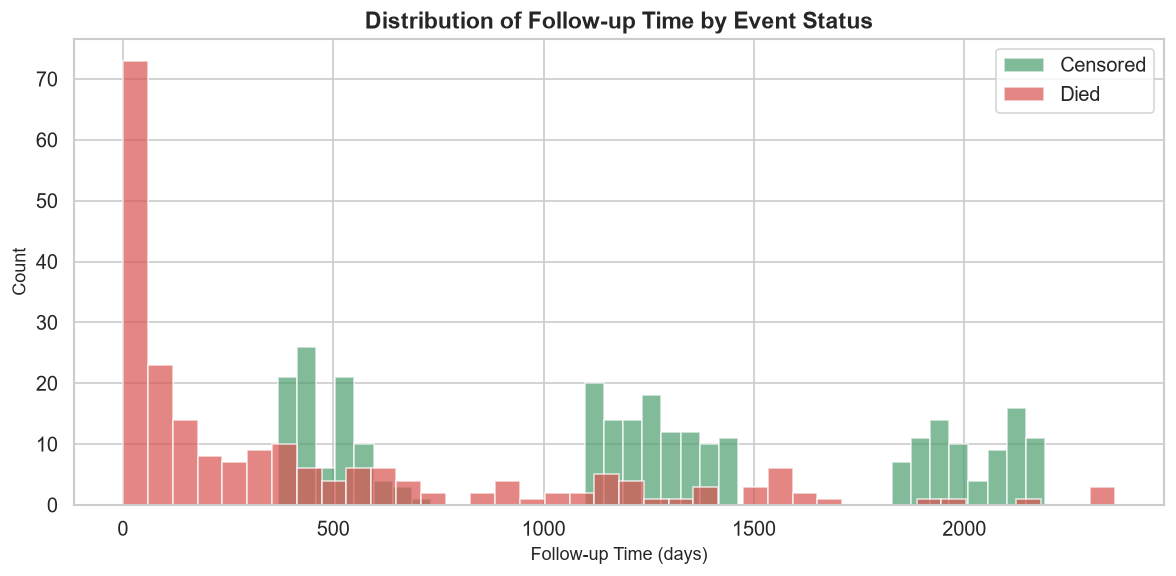

In [8]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(df.loc[df['event']==0, 'time'], bins=40, alpha=0.7, label='Censored',
        color='#4c9f70', edgecolor='white')
ax.hist(df.loc[df['event']==1, 'time'], bins=40, alpha=0.7, label='Died',
        color='#d9534f', edgecolor='white')
ax.set_xlabel('Follow-up Time (days)')
ax.set_ylabel('Count')
ax.set_title('Distribution of Follow-up Time by Event Status', fontsize=14, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

## 3. Kaplan-Meier Survival Estimation

The Kaplan-Meier estimator is a non-parametric method that estimates the survival function
$S(t) = P(T > t)$ directly from observed event and censoring times.

### 3.1 Overall Survival Curve

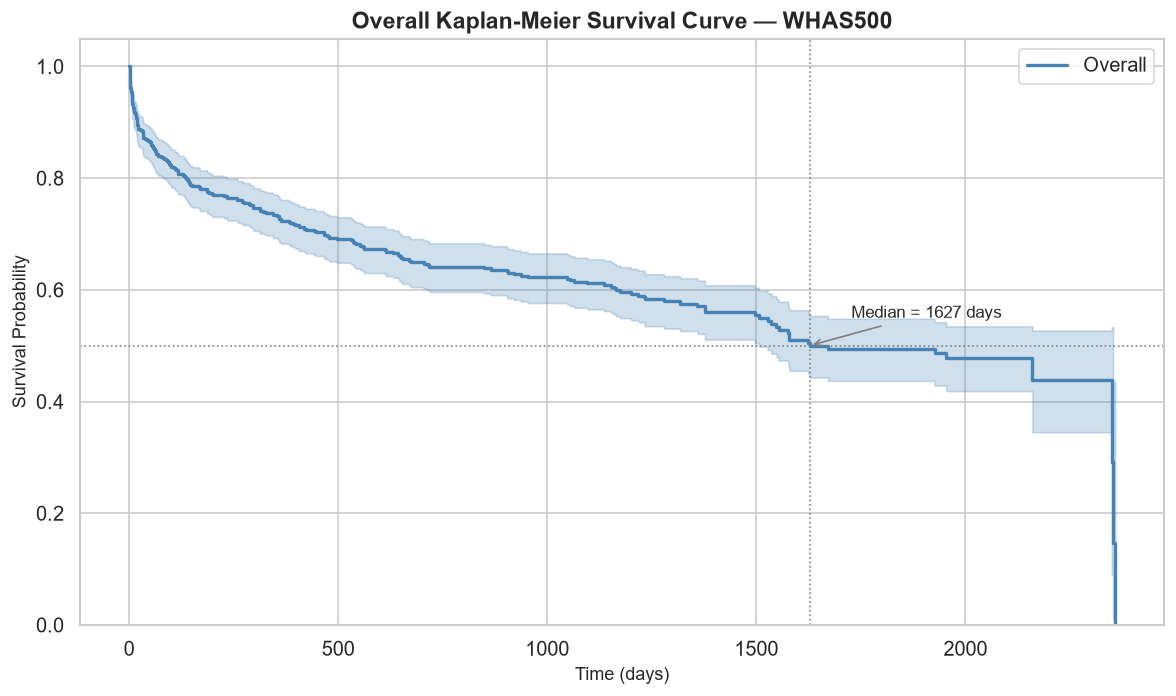

Median survival time: 1627 days

Survival probabilities at key time points:
    365 days (1y): 0.724
    730 days (2y): 0.642
   1095 days (3y): 0.614
   1825 days (5y): 0.494


In [9]:
kmf = KaplanMeierFitter()
kmf.fit(df['time'], event_observed=df['event'], label='Overall')

fig, ax = plt.subplots(figsize=(10, 6))
kmf.plot_survival_function(ax=ax, ci_show=True, color='steelblue', lw=2)
ax.set_title('Overall Kaplan-Meier Survival Curve — WHAS500', fontsize=14, fontweight='bold')
ax.set_xlabel('Time (days)')
ax.set_ylabel('Survival Probability')

median_surv = kmf.median_survival_time_
if not np.isinf(median_surv):
    ax.axhline(0.5, color='gray', ls=':', lw=1)
    ax.axvline(median_surv, color='gray', ls=':', lw=1)
    ax.annotate(f'Median = {median_surv:.0f} days', xy=(median_surv, 0.5),
                xytext=(median_surv + 100, 0.55), fontsize=10,
                arrowprops=dict(arrowstyle='->', color='gray'))

ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.show()

print(f"Median survival time: {median_surv:.0f} days")
print(f"\nSurvival probabilities at key time points:")
for t in [365, 730, 1095, 1825]:
    prob = kmf.predict(t)
    print(f"  {t:>5d} days ({t//365}y): {prob:.3f}")

### 3.2 Stratified Kaplan-Meier Curves

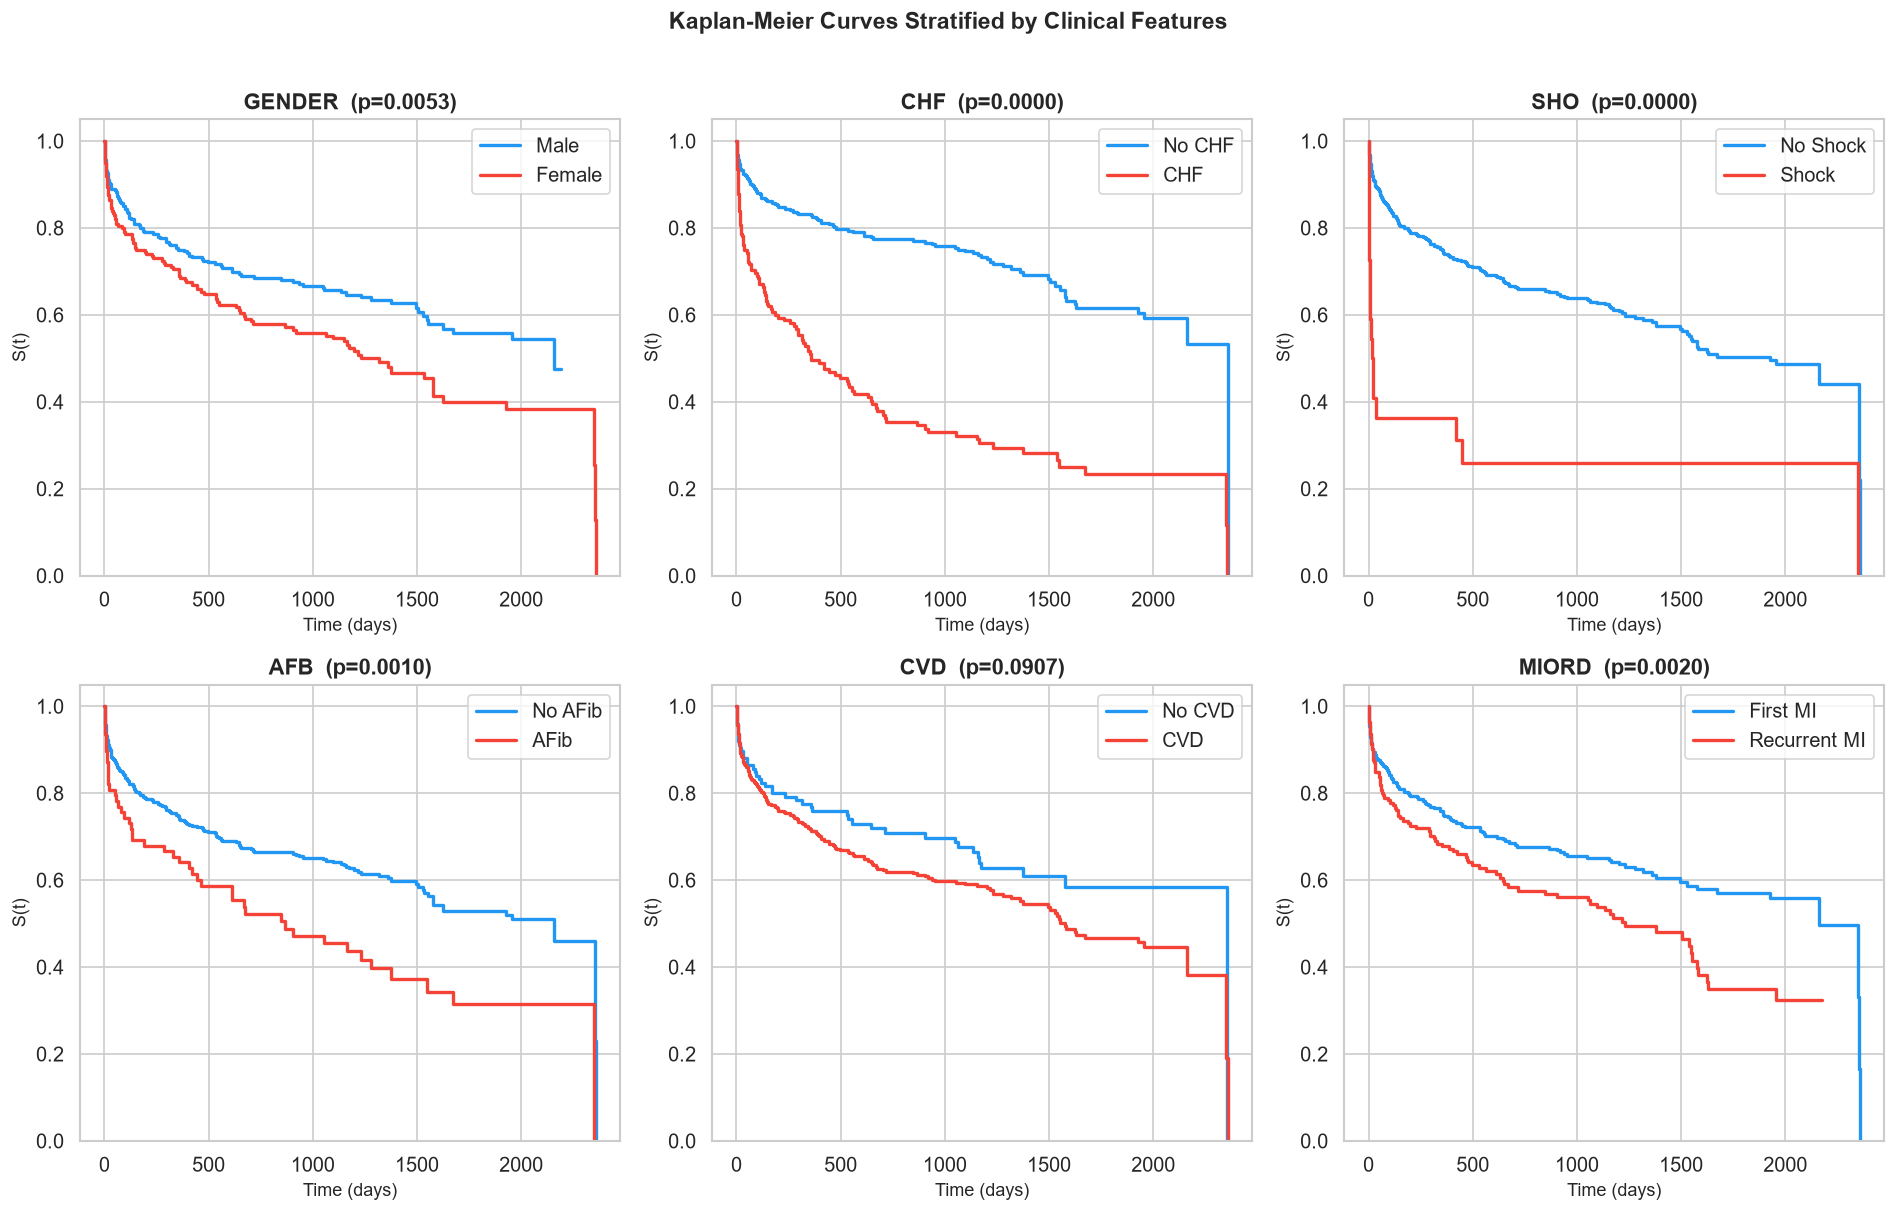

In [10]:
strat_vars = {
    'gender': {0: 'Male', 1: 'Female'},
    'chf': {0: 'No CHF', 1: 'CHF'},
    'sho': {0: 'No Shock', 1: 'Shock'},
    'afb': {0: 'No AFib', 1: 'AFib'},
    'cvd': {0: 'No CVD', 1: 'CVD'},
    'miord': {0: 'First MI', 1: 'Recurrent MI'}
}

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
colors = ['#2196F3', '#F44336']

for ax, (var, labels) in zip(axes.ravel(), strat_vars.items()):
    for i, (val, lbl) in enumerate(labels.items()):
        mask = df[var] == val
        kmf_i = KaplanMeierFitter()
        kmf_i.fit(df.loc[mask, 'time'], event_observed=df.loc[mask, 'event'], label=lbl)
        kmf_i.plot_survival_function(ax=ax, ci_show=False, color=colors[i], lw=2)

    g0 = df[var] == 0
    lr = logrank_test(df.loc[g0, 'time'], df.loc[~g0, 'time'],
                      event_observed_A=df.loc[g0, 'event'],
                      event_observed_B=df.loc[~g0, 'event'])
    ax.set_title(f'{var.upper()}  (p={lr.p_value:.4f})', fontweight='bold')
    ax.set_xlabel('Time (days)')
    ax.set_ylabel('S(t)')
    ax.set_ylim(0, 1.05)

plt.suptitle('Kaplan-Meier Curves Stratified by Clinical Features',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

### 3.3 Kaplan-Meier by Age Group

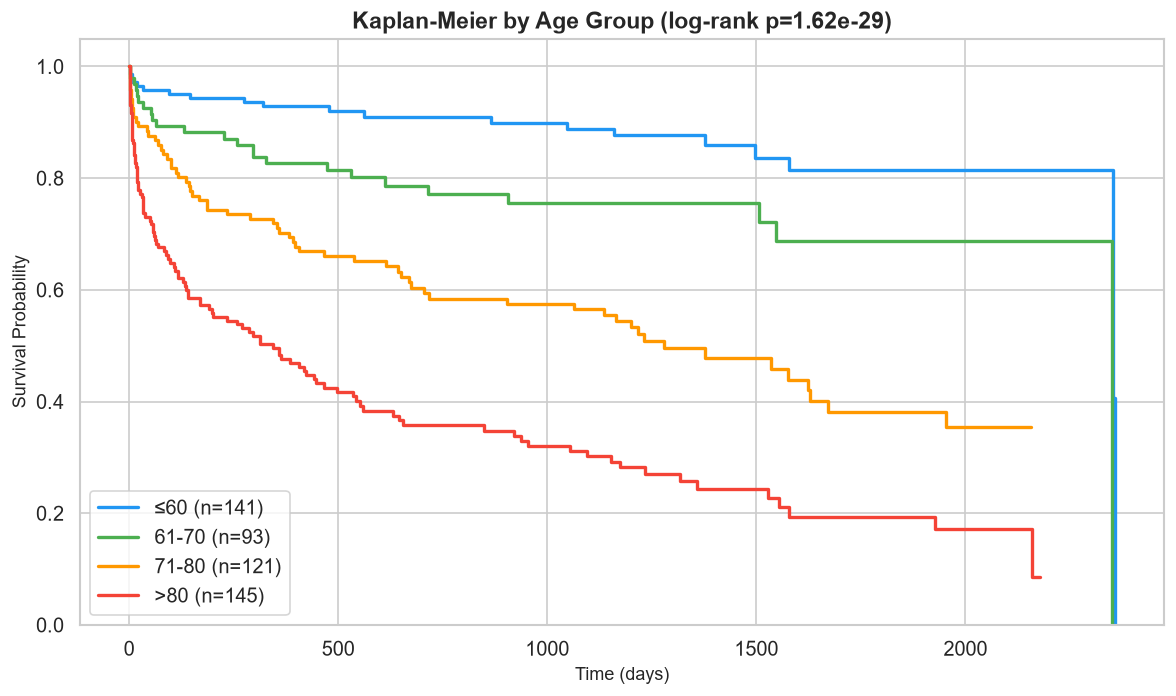

In [11]:
df['age_group'] = pd.cut(df['age'], bins=[0, 60, 70, 80, 110],
                        labels=['≤60', '61-70', '71-80', '>80'])

fig, ax = plt.subplots(figsize=(10, 6))
age_colors = ['#2196F3', '#4CAF50', '#FF9800', '#F44336']

for i, grp in enumerate(['≤60', '61-70', '71-80', '>80']):
    mask = df['age_group'] == grp
    kmf_a = KaplanMeierFitter()
    kmf_a.fit(df.loc[mask, 'time'], event_observed=df.loc[mask, 'event'],
              label=f'{grp} (n={mask.sum()})')
    kmf_a.plot_survival_function(ax=ax, ci_show=False, color=age_colors[i], lw=2)

mlr = multivariate_logrank_test(df['time'], df['age_group'], df['event'])
ax.set_title(f'Kaplan-Meier by Age Group (log-rank p={mlr.p_value:.2e})',
             fontsize=14, fontweight='bold')
ax.set_xlabel('Time (days)')
ax.set_ylabel('Survival Probability')
ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.show()

df.drop(columns='age_group', inplace=True)

## 4. Cox Proportional Hazards Regression

The Cox PH model estimates hazard ratios without assuming a baseline hazard distribution:
$$h(t|X) = h_0(t) \exp(\beta^\top X)$$

### 4.1 Univariate Cox Regression

In [12]:
features = [c for c in df.columns if c not in ('time', 'event')]
uni_results = []

for col in features:
    cph_uni = CoxPHFitter()
    cph_uni.fit(df[[col, 'time', 'event']], duration_col='time', event_col='event')
    s = cph_uni.summary.iloc[0]
    uni_results.append({
        'Variable': col,
        'HR': np.exp(s['coef']),
        'HR_lower': np.exp(s['coef lower 95%']),
        'HR_upper': np.exp(s['coef upper 95%']),
        'p_value': s['p'],
        'Concordance': cph_uni.concordance_index_
    })

uni_df = pd.DataFrame(uni_results).sort_values('p_value')
uni_df['Significant'] = uni_df['p_value'].apply(
    lambda p: '***' if p < 0.001 else ('**' if p < 0.01 else ('*' if p < 0.05 else ''))
)
display(uni_df.round(4))

,Variable,HR,HR_lower,HR_upper,p_value,Concordance,Significant
1,age,1.0686,1.0559,1.0814,0.0000,0.7312,***
4,chf,3.3191,2.5324,4.3501,0.0000,0.6422,***
3,bmi,0.9062,0.8804,0.9328,0.0000,0.6485,***
8,hr,1.0152,1.0098,1.0205,0.0000,0.6140,***
6,diasbp,0.9841,0.9778,0.9905,0.0000,0.6114,***
12,sho,3.2885,1.9903,5.4335,0.0000,0.5357,***
11,mitype,0.5169,0.3725,0.7173,0.0001,0.5574,***
0,afb,1.7156,1.2405,2.3726,0.0011,0.5368,**
10,miord,1.5320,1.1665,2.0122,0.0022,0.5404,**
7,gender,1.4645,1.1183,1.9178,0.0056,0.5417,**


### 4.2 Multivariate Cox PH Model

In [13]:
cox_cols = features + ['time', 'event']

cph = CoxPHFitter()
cph.fit(df[cox_cols], duration_col='time', event_col='event')

print("=== Multivariate Cox PH Summary ===")
cph.print_summary(columns=['coef', 'exp(coef)', 'exp(coef) lower 95%',
                            'exp(coef) upper 95%', 'p'])
print(f"\nConcordance Index: {cph.concordance_index_:.4f}")

=== Multivariate Cox PH Summary ===


<lifelines.CoxPHFitter: fitted with 500 total observations, 285 right-censored observations>
             duration col = 'time'
                event col = 'event'
      baseline estimation = breslow
   number of observations = 500
number of events observed = 215
   partial log-likelihood = -1114.58
         time fit was run = 2026-10-12 20:39:22 UTC

---
           coef exp(coef) exp(coef) lower 95% exp(coef) upper 95%      p
covariate                                                               
afb        0.04      1.04                0.73                1.48   0.84
age        0.05      1.05                1.03                1.06 <0.005
av3        0.31      1.37                0.59                3.18   0.47
bmi       -0.05      0.95                0.92                0.99 <0.005
chf        0.73      2.08                1.54                2.81 <0.005
cvd       -0.06      0.95                0.67                1.34   0.76
diasbp    -0.01      0.99                0.98                1.00   0.01
gender    -0.29      0.75                0.56                0.99   0.04
hr         0.01      1.01                1.01                1.02 <0.005
los       -0.01      0.99                0.96                1.02   0.65
miord      0.08      1.09                0.81                1.46   0.58
mitype    -0.24      0.79                0.54                1.15   0.22
sho        1.24      3.45                1.96                6.09 <0.005
sysbp      0.00      1.00                1.00                1.01   0.60
---
Concordance = 0.78
Partial AIC = 2257.16
log-likelihood ratio test = 225.48 on 14 df
-log2(p) of ll-ratio test = 131.16


Concordance Index: 0.7842


### 4.3 Forest Plot of Hazard Ratios

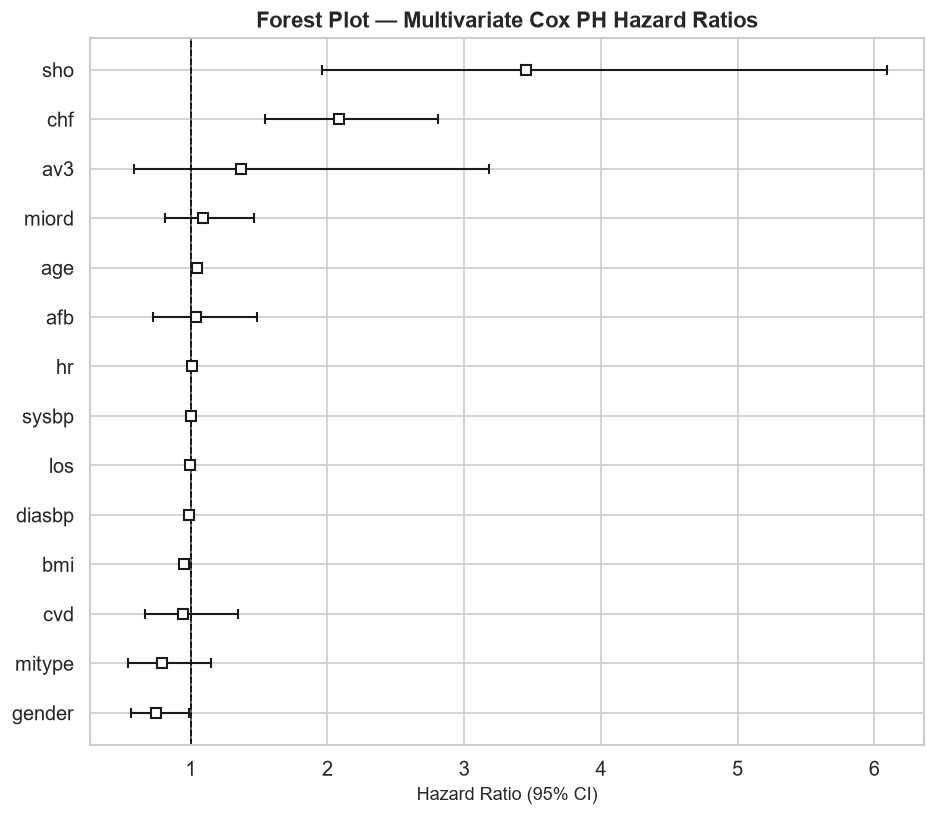

In [14]:
fig, ax = plt.subplots(figsize=(8, 7))
cph.plot(ax=ax, hazard_ratios=True)
ax.axvline(1, color='black', ls='--', lw=1)
ax.set_title('Forest Plot — Multivariate Cox PH Hazard Ratios',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Hazard Ratio (95% CI)')
plt.tight_layout()
plt.show()

### 4.4 Proportional Hazards Assumption Check

=== Schoenfeld Residuals Test ===


   Bootstrapping lowess lines. May take a moment...




   Bootstrapping lowess lines. May take a moment...




   Bootstrapping lowess lines. May take a moment...




   Bootstrapping lowess lines. May take a moment...




   Bootstrapping lowess lines. May take a moment...



...



1. Variable 'los' failed the non-proportional test: p-value is 0.0102.

   Advice 1: the functional form of the variable 'los' might be incorrect. That is, there may be
non-linear terms missing. The proportional hazard test used is very sensitive to incorrect
functional forms. See documentation in link [D] below on how to specify a functional form.

   Advice 2: try binning the variable 'los' using pd.cut, and then specify it in `strata=['los',
...]` in the call in `.fit`. See documentation in link [B] below.

   Advice 3: try adding an interaction term with your time variable. See documentation in link [C]
below.


   Bootstrapping lowess lines. May take a moment...




   Bootstrapping lowess lines. May take a moment...




2. Variable 'mitype' failed the non-proportional test: p-value is 0.0480.

   Advice: with so few unique values (only 2), you can include `strata=['mitype', ...]` in the call
in `.fit`. See documentation in link [E] below.

   Bootstrapping lowess lines. May take a moment...




3. Variable 'sho' failed the non-proportional test: p-value is 0.0040.

   Advice: with so few unique values (only 2), you can include `strata=['sho', ...]` in the call in
`.fit`. See documentation in link [E] below.

   Bootstrapping lowess lines. May take a moment...




---
[A]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html
[B]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html#Bin-variable-and-stratify-on-it
[C]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html#Introduce-time-varying-covariates
[D]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html#Modify-the-functional-form
[E]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html#Stratification



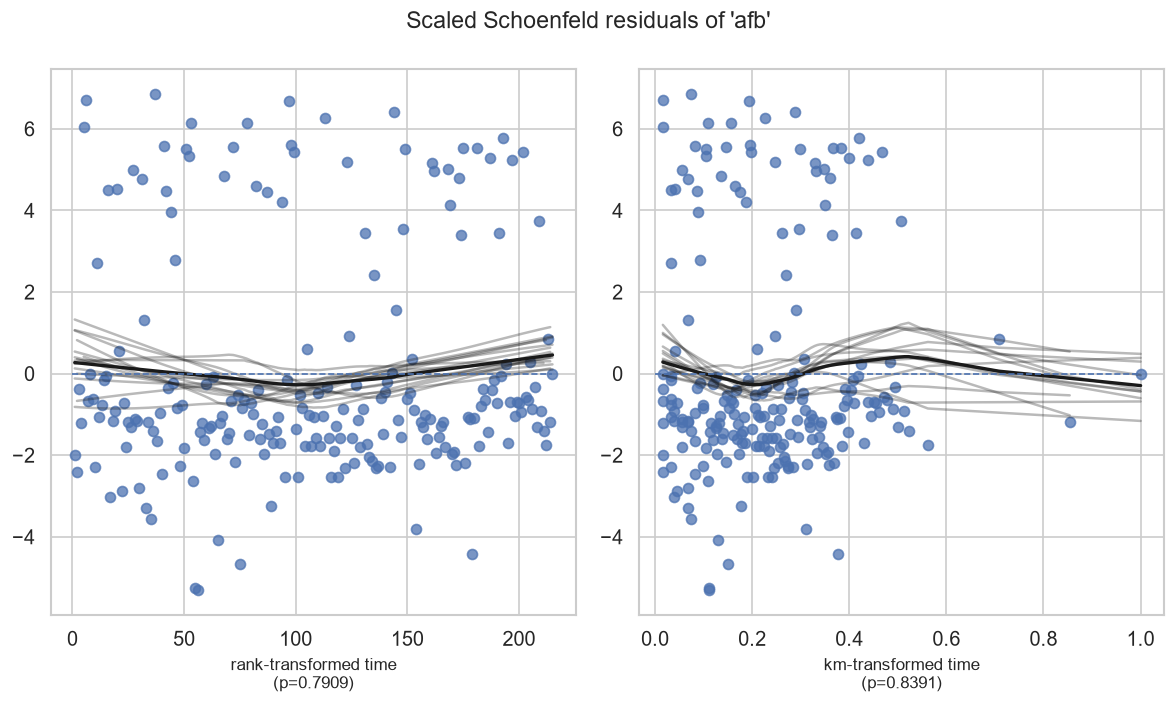

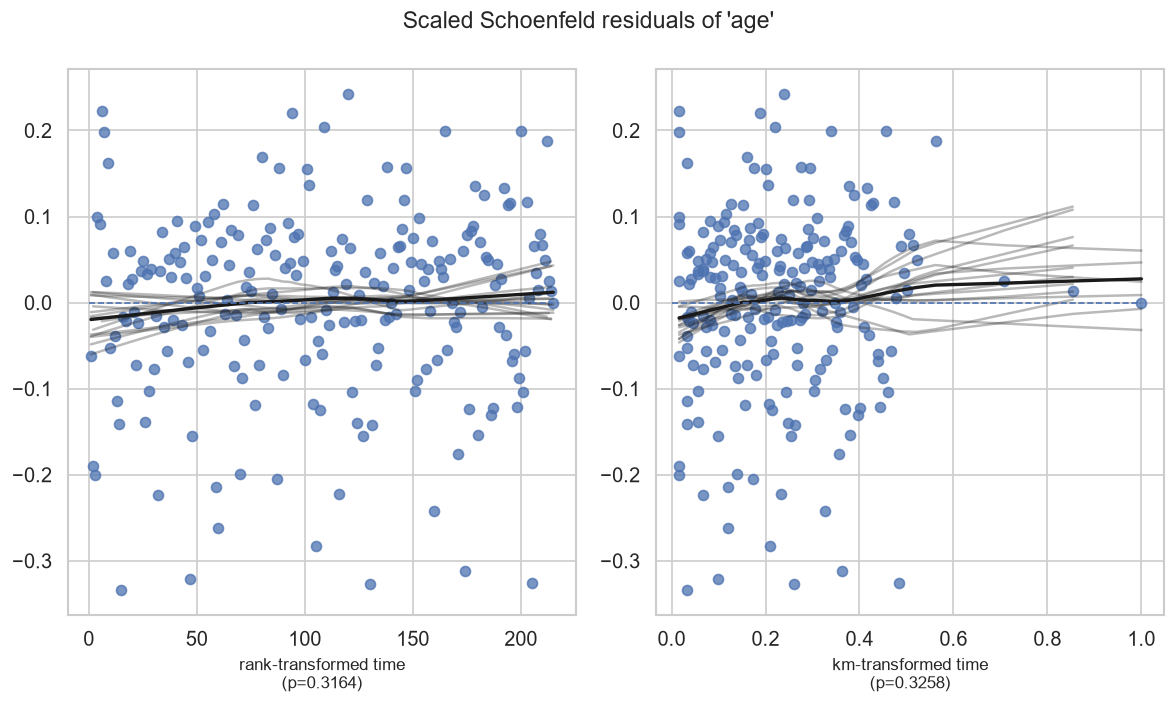

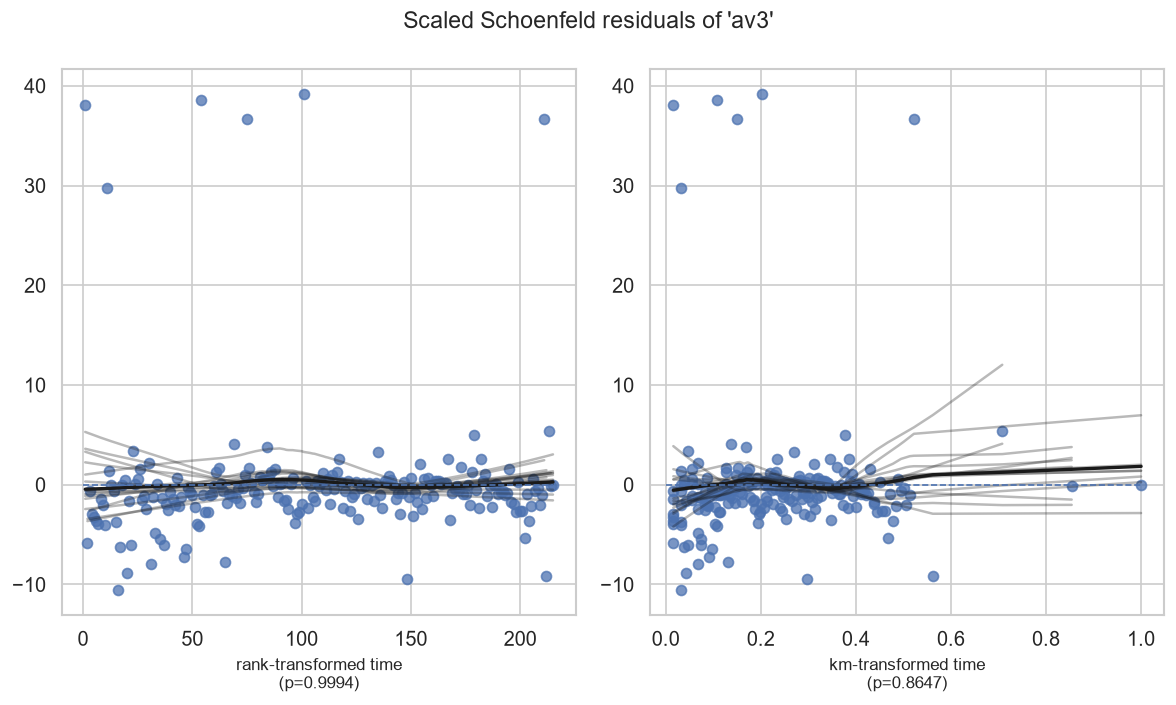

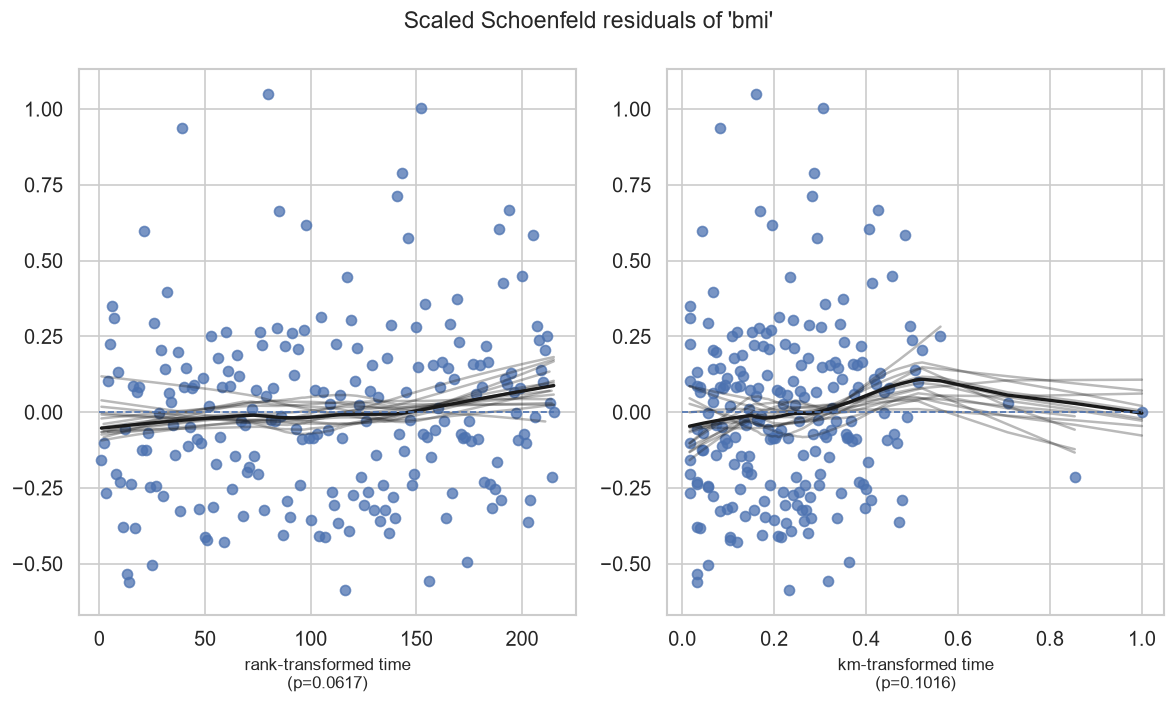

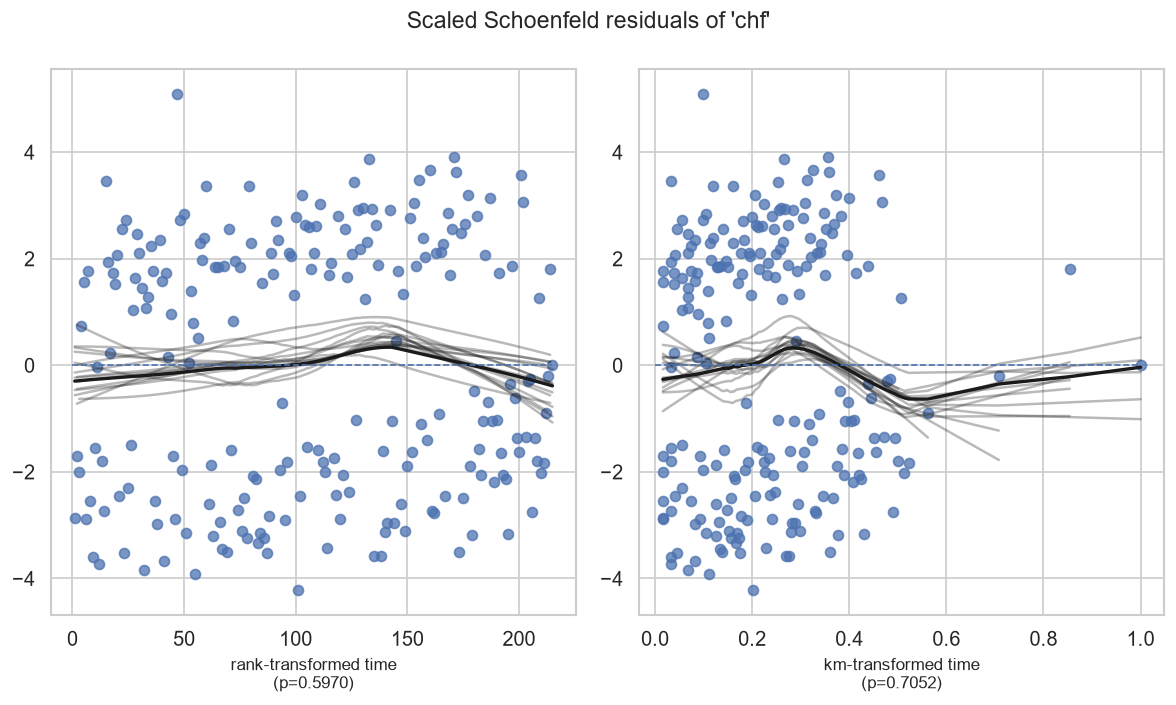

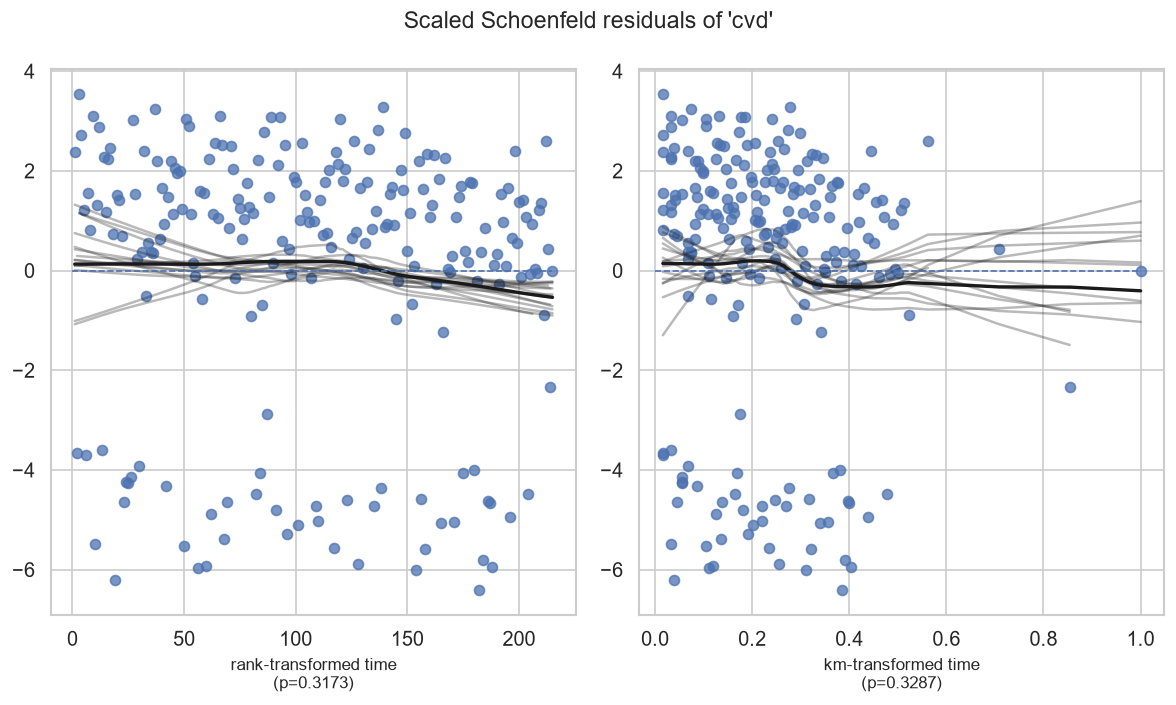

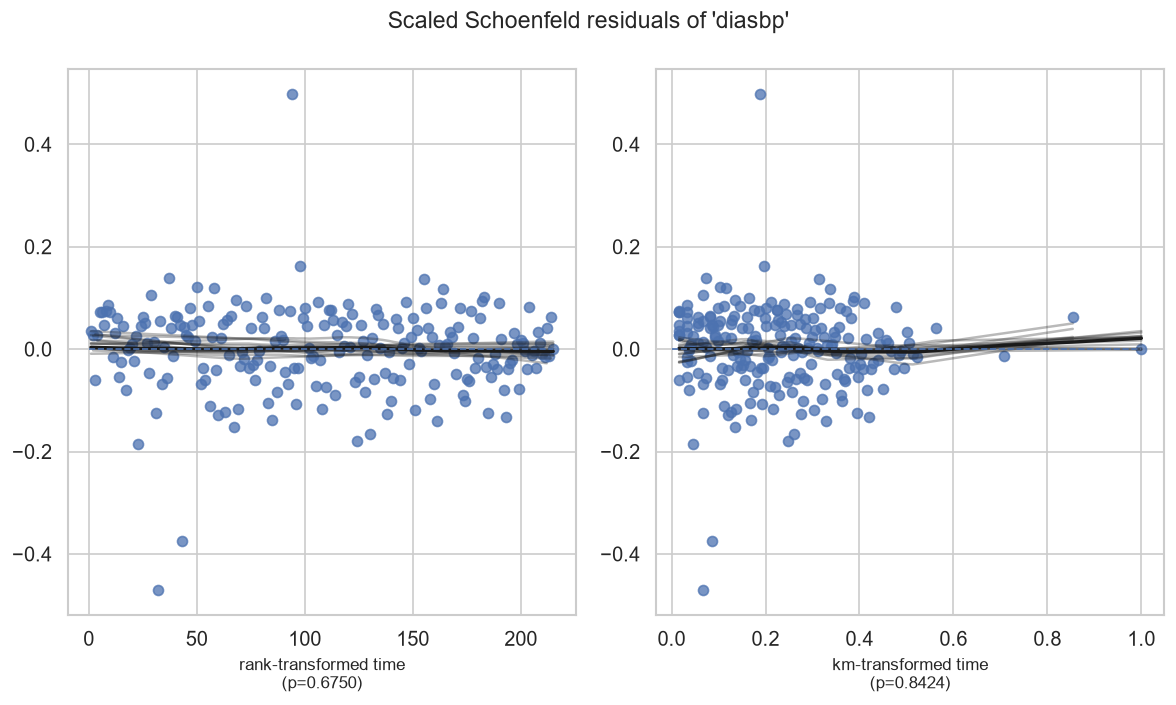

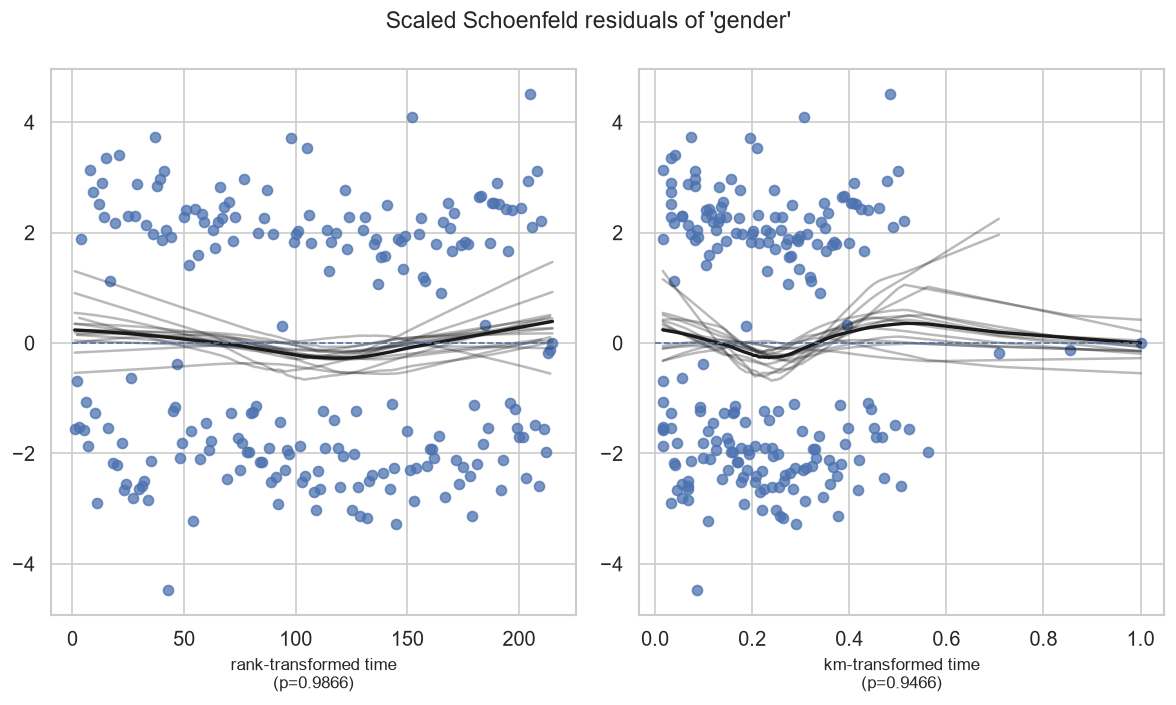

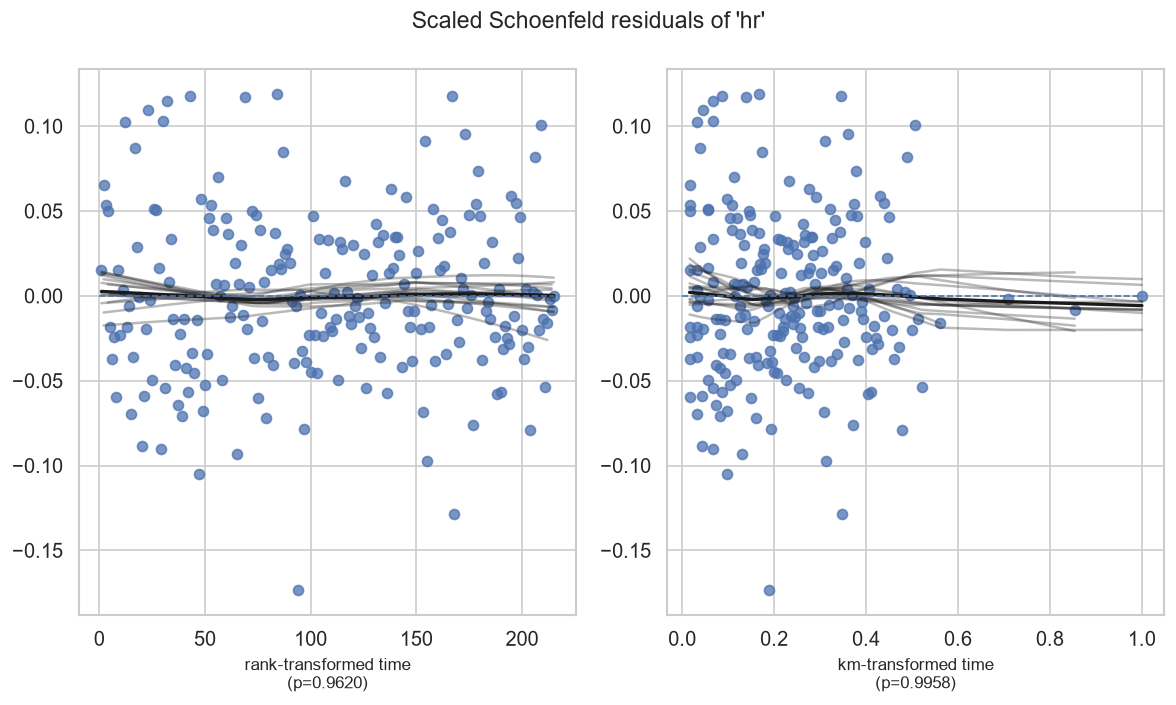

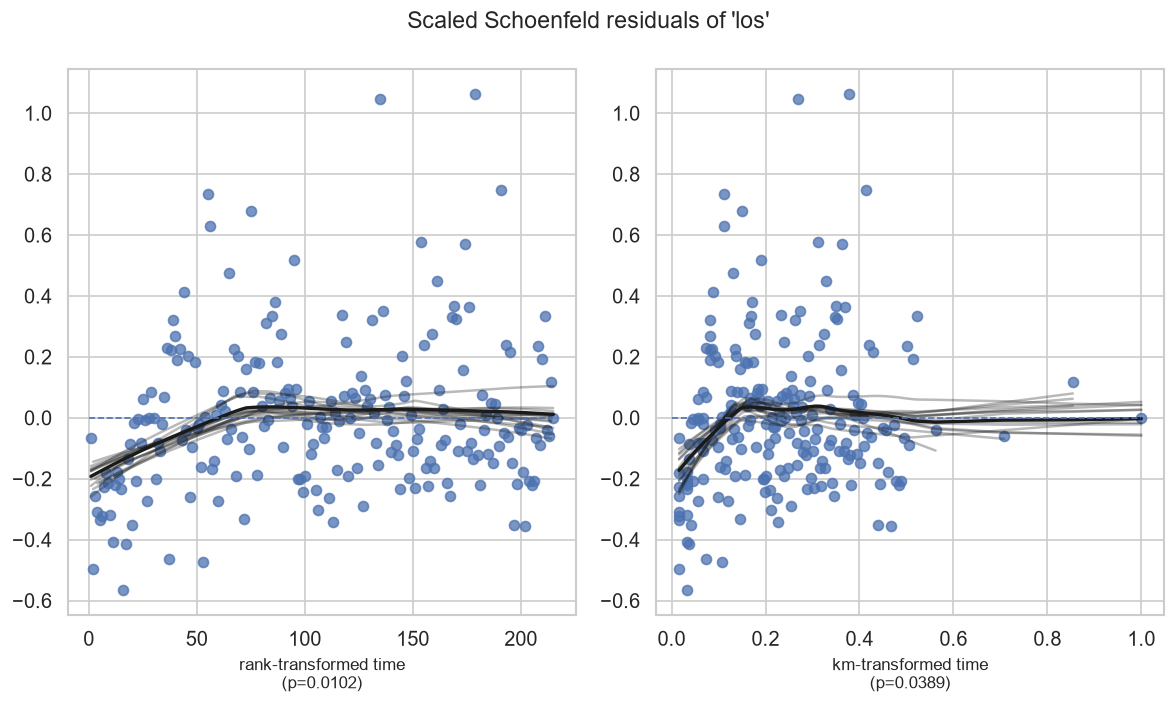

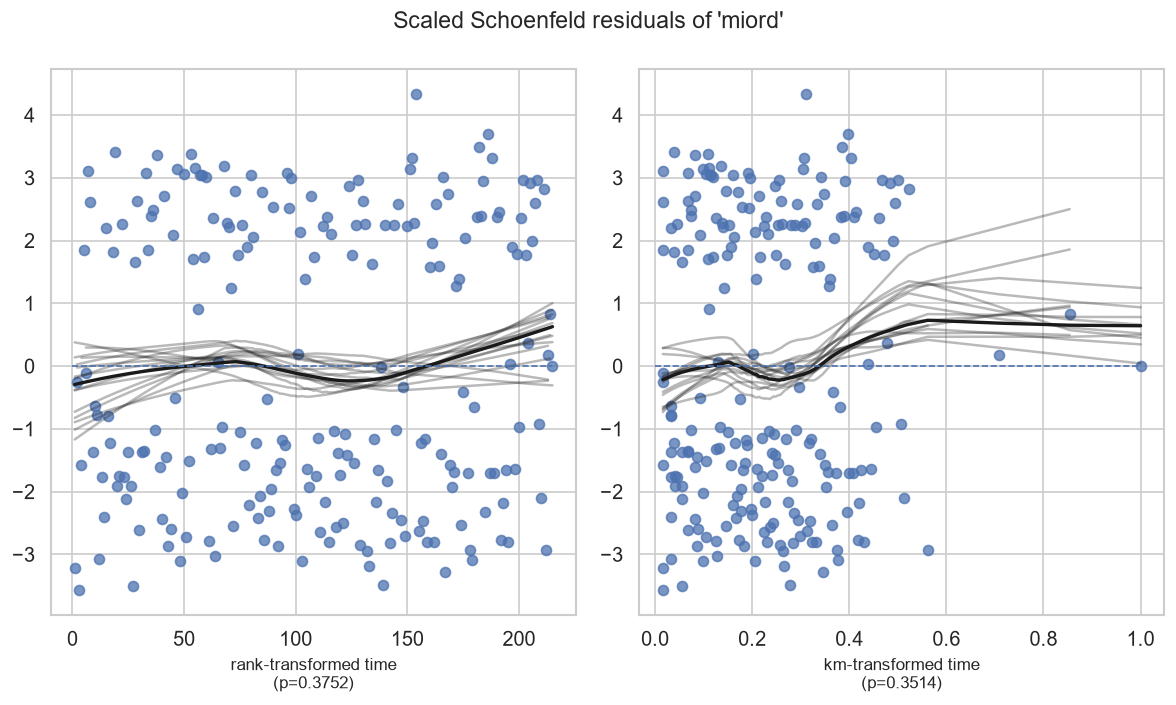

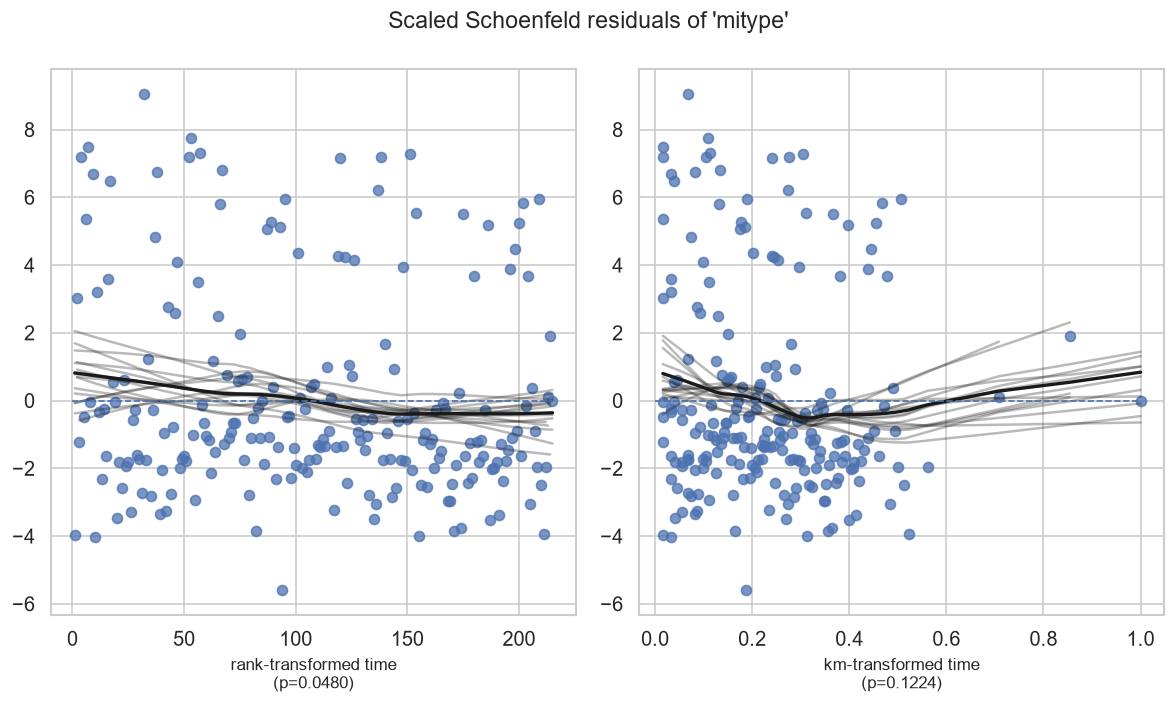

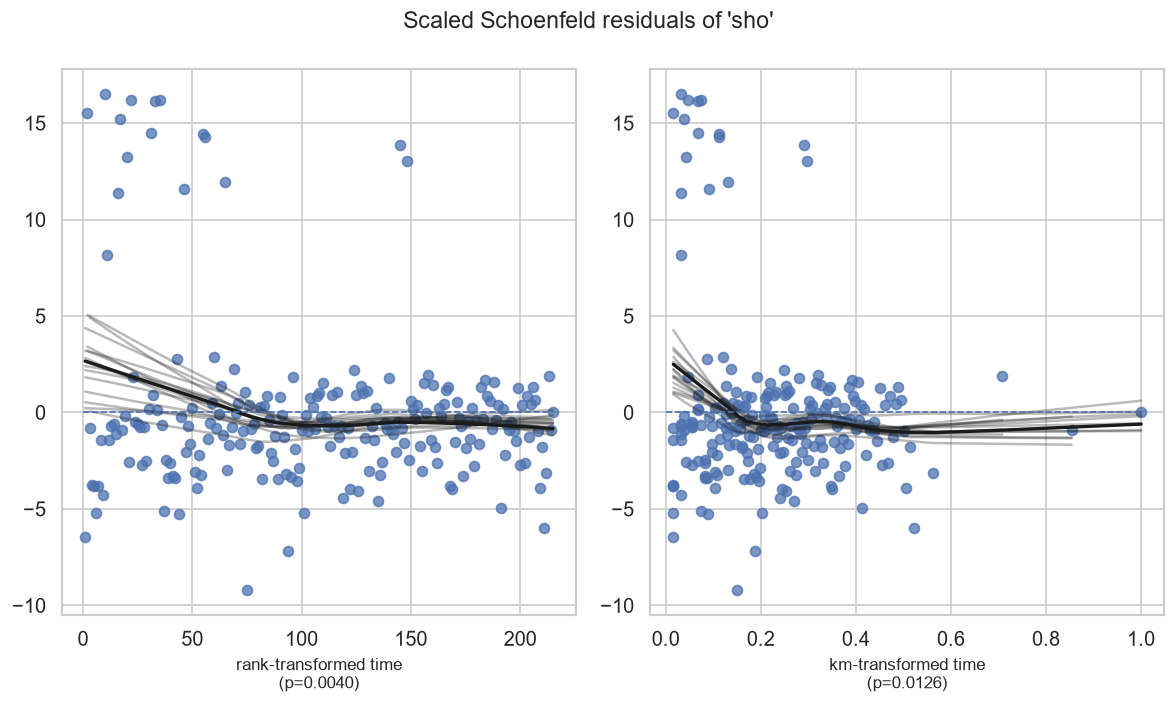

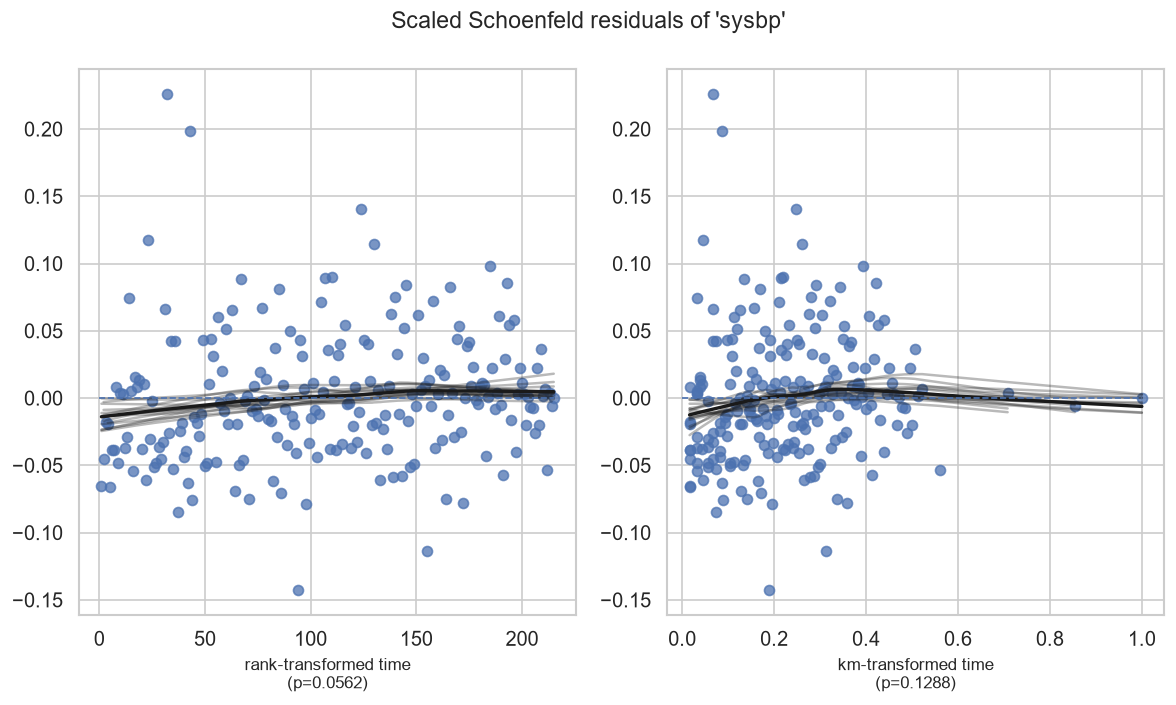

In [15]:
print("=== Schoenfeld Residuals Test ===\n")
ph_test = cph.check_assumptions(df[cox_cols],
                                 p_value_threshold=0.05,
                                 show_plots=True)

### 4.5 Addressing PH Violations — Stratified Cox Model

The Schoenfeld test flags **`sho`**, **`mitype`** and **`los`**. Because `sho` and `mitype` are binary,
we stratify on them: each of the four strata gets its own baseline hazard $h_{0s}(t)$, while the
remaining covariates share common hazard ratios. The trade-off is that no hazard ratio is estimated
for the stratification variables, so their effect is assessed with Kaplan-Meier curves and log-rank
tests (Section 3.2) instead.

This stratified model is the **final Cox model** used for prediction and model comparison below.

In [16]:
strata_vars = ['sho', 'mitype']
cox_name = 'Cox PH (stratified)'

cph_strat = CoxPHFitter()
cph_strat.fit(df[cox_cols], duration_col='time', event_col='event', strata=strata_vars)

print(f"=== Stratified Cox PH (strata: {', '.join(strata_vars)}) ===")
cph_strat.print_summary(columns=['coef', 'exp(coef)', 'exp(coef) lower 95%',
                                  'exp(coef) upper 95%', 'p'])

ph_strat = proportional_hazard_test(cph_strat, df[cox_cols], time_transform='rank')
print("\n=== Schoenfeld Test After Stratification ===")
display(ph_strat.summary[['test_statistic', 'p']].sort_values('p').round(4))
print(f"Covariates violating PH at p < 0.05: {(ph_strat.summary['p'] < 0.05).sum()}")

# Partial hazards are not comparable across strata, so patients are ranked by
# predicted (restricted) mean survival time instead
strat_ci = lifelines_ci(df['time'], cph_strat.predict_expectation(df[features]).squeeze(), df['event'])
print(f"\nIn-sample C-index (stratified Cox): {strat_ci:.4f}")

# Sensitivity check: refit without implausible diastolic BP values
keep = df['diasbp'] >= 20
cph_sens = CoxPHFitter().fit(df.loc[keep, cox_cols], duration_col='time', event_col='event',
                             strata=strata_vars)
hr_change = (np.exp(cph_sens.params_) / np.exp(cph_strat.params_) - 1).abs()
print(f"Excluding {(~keep).sum()} rows with diasbp < 20: largest HR change = "
      f"{hr_change.max():.1%} ({hr_change.idxmax()})")

=== Stratified Cox PH (strata: sho, mitype) ===


<lifelines.CoxPHFitter: fitted with 500 total observations, 285 right-censored observations>
             duration col = 'time'
                event col = 'event'
                   strata = ['sho', 'mitype']
      baseline estimation = breslow
   number of observations = 500
number of events observed = 215
   partial log-likelihood = -958.33
         time fit was run = 2026-10-12 20:39:32 UTC

---
           coef exp(coef) exp(coef) lower 95% exp(coef) upper 95%      p
covariate                                                               
afb        0.06      1.07                0.75                1.52   0.72
age        0.05      1.05                1.03                1.06 <0.005
av3        0.46      1.59                0.67                3.76   0.29
bmi       -0.05      0.96                0.92                0.99   0.01
chf        0.73      2.07                1.53                2.81 <0.005
cvd       -0.08      0.92                0.65                1.31   0.65
diasbp    -0.01      0.99                0.98                1.00   0.01
gender    -0.30      0.74                0.55                0.99   0.04
hr         0.01      1.01                1.01                1.02 <0.005
los       -0.01      0.99                0.96                1.02   0.57
miord      0.05      1.05                0.78                1.42   0.73
sysbp      0.00      1.00                1.00                1.01   0.64
---
Concordance = 0.76
Partial AIC = 1940.65
log-likelihood ratio test = 179.26 on 12 df
-log2(p) of ll-ratio test = 103.71


=== Schoenfeld Test After Stratification ===


,test_statistic,p
bmi,1.2570,0.2622
age,0.8840,0.3471
miord,0.6573,0.4175
hr,0.2751,0.5999
diasbp,0.2684,0.6044
gender,0.2207,0.6385
av3,0.1799,0.6714
sysbp,0.1119,0.7380
cvd,0.0387,0.8441
afb,0.0193,0.8894


Covariates violating PH at p < 0.05: 0

In-sample C-index (stratified Cox): 0.7827


Excluding 2 rows with diasbp < 20: largest HR change = 1.4% (chf)


### 4.6 Stratified Cox PH — 5-Fold Cross-Validation

In [17]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
cox_cv_scores = []

for fold, (train_idx, test_idx) in enumerate(kf.split(df), 1):
    train = df.iloc[train_idx]
    test = df.iloc[test_idx]

    cph_cv = CoxPHFitter()
    cph_cv.fit(train[cox_cols], duration_col='time', event_col='event', strata=strata_vars)

    preds = cph_cv.predict_expectation(test[features]).squeeze()
    ci = lifelines_ci(test['time'], preds.values, test['event'])
    cox_cv_scores.append(ci)
    print(f"  Fold {fold}: C-index = {ci:.4f}")

print(f"\n  Mean C-index: {np.mean(cox_cv_scores):.4f} ± {np.std(cox_cv_scores):.4f}")

  Fold 1: C-index = 0.6947


  Fold 2: C-index = 0.7910


  Fold 3: C-index = 0.7430


  Fold 4: C-index = 0.7656


  Fold 5: C-index = 0.7978

  Mean C-index: 0.7584 ± 0.0373


## 5. Accelerated Failure Time (AFT) Models

Unlike Cox PH, AFT models directly model survival *time* rather than the hazard:
$$\log(T) = \mu + \beta^\top X + \sigma W$$

We fit three parametric distributions: **Weibull**, **Log-Normal**, and **Log-Logistic**.

### 5.1 Parametric AFT Model Comparison

In [18]:
aft_models = {
    'Weibull': WeibullAFTFitter(),
    'Log-Normal': LogNormalAFTFitter(),
    'Log-Logistic': LogLogisticAFTFitter(),
}

n_obs = len(df)
aft_results = {}
for name, model in aft_models.items():
    model.fit(df[cox_cols], duration_col='time', event_col='event')
    k = len(model.params_)  # all fitted parameters, including intercepts and shape
    aft_results[name] = {
        'AIC': model.AIC_,
        'BIC': -2 * model.log_likelihood_ + k * np.log(n_obs),
        'Concordance': model.concordance_index_,
        'Log-Likelihood': model.log_likelihood_,
    }
    print(f"  {name:15s}  AIC={model.AIC_:10.1f}  C-index={model.concordance_index_:.4f}")

aft_comp = pd.DataFrame(aft_results).T
print("\n=== AFT Model Comparison ===")
display(aft_comp.round(4))

  Weibull          AIC=    3311.6  C-index=0.7846


  Log-Normal       AIC=    3323.8  C-index=0.7859


  Log-Logistic     AIC=    3315.2  C-index=0.7861

=== AFT Model Comparison ===


,AIC,BIC,Concordance,Log-Likelihood
Weibull,3311.6353,3379.0690,0.7846,-1639.8177
Log-Normal,3323.8242,3391.2579,0.7859,-1645.9121
Log-Logistic,3315.2232,3382.6569,0.7861,-1641.6116


### 5.2 Best AFT Model — Detailed Results

In [19]:
best_aft_name = aft_comp['AIC'].idxmin()
best_aft = aft_models[best_aft_name]
print(f"Best AFT distribution by AIC: {best_aft_name}\n")
best_aft.print_summary(columns=['coef', 'exp(coef)', 'p'])

Best AFT distribution by AIC: Weibull



<lifelines.WeibullAFTFitter: fitted with 500 total observations, 285 right-censored observations>
             duration col = 'time'
                event col = 'event'
   number of observations = 500
number of events observed = 215
           log-likelihood = -1639.82
         time fit was run = 2026-10-12 20:39:34 UTC

---
                   coef exp(coef)      p
param   covariate                       
lambda_ afb       -0.03      0.97   0.93
        age       -0.08      0.92 <0.005
        av3       -0.90      0.41   0.23
        bmi        0.08      1.09 <0.005
        chf       -1.32      0.27 <0.005
        cvd        0.09      1.09   0.78
        diasbp     0.02      1.02   0.02
        gender     0.48      1.62   0.06
        hr        -0.02      0.98 <0.005
        los        0.01      1.01   0.63
        miord     -0.12      0.89   0.65
        mitype     0.42      1.52   0.23
        sho       -2.35      0.10 <0.005
        sysbp     -0.00      1.00   0.75
        Intercept 12.62  3.04e+05 <0.005
rho_    Intercept -0.59      0.56 <0.005
---
Concordance = 0.78
AIC = 3311.64
log-likelihood ratio test = 225.27 on 14 df
-log2(p) of ll-ratio test = 131.02

### 5.3 Acceleration Factors (Best AFT)

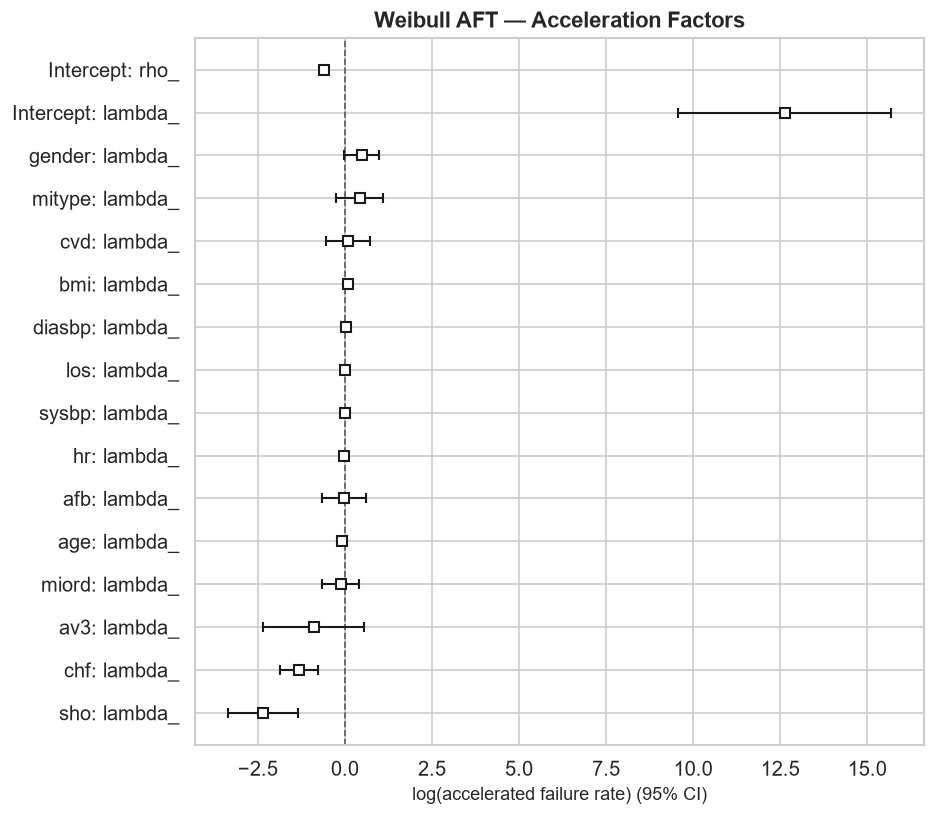

In [20]:
fig, ax = plt.subplots(figsize=(8, 7))
best_aft.plot(ax=ax)
ax.set_title(f'{best_aft_name} AFT — Acceleration Factors',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

### 5.4 Individual Predicted Survival Curves

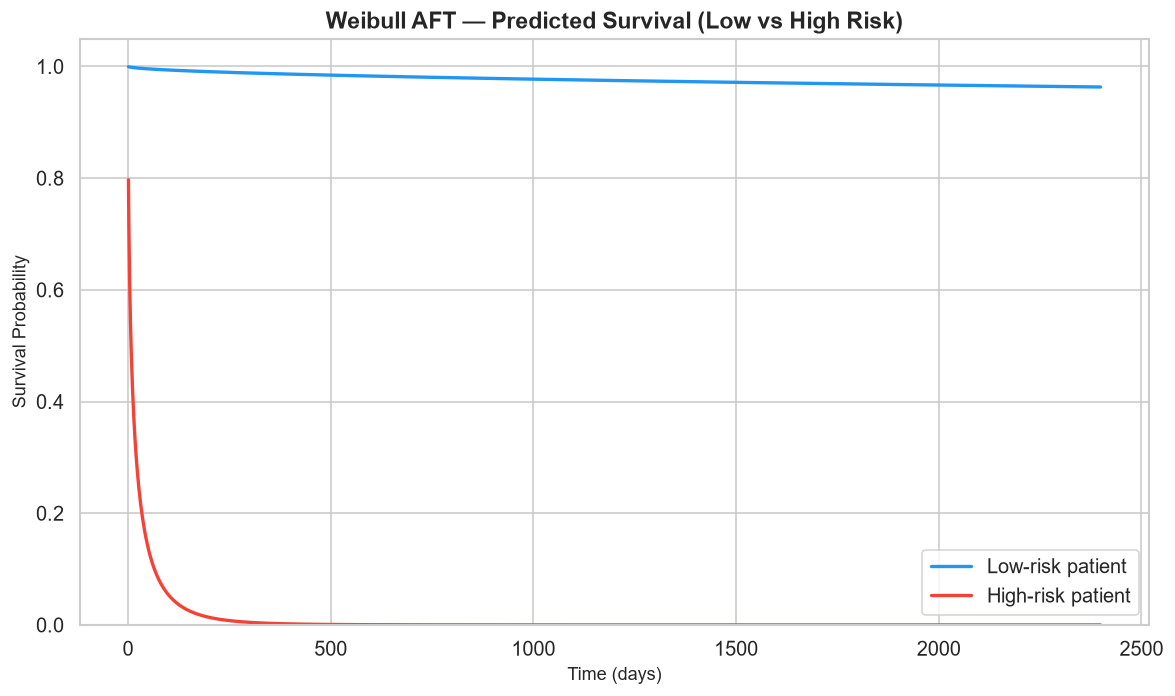

In [21]:
exp_surv = cph_strat.predict_expectation(df[features]).squeeze()
low_risk_idx = int(exp_surv.idxmax())
high_risk_idx = int(exp_surv.idxmin())

fig, ax = plt.subplots(figsize=(10, 6))
times_plot = np.arange(1, 2400)

for idx, label, color in [(low_risk_idx, 'Low-risk patient', '#2196F3'),
                           (high_risk_idx, 'High-risk patient', '#F44336')]:
    surv = best_aft.predict_survival_function(df.iloc[[idx]], times=times_plot)
    ax.plot(times_plot, surv.values.ravel(), label=label, color=color, lw=2)

ax.set_title(f'{best_aft_name} AFT — Predicted Survival (Low vs High Risk)',
             fontsize=14, fontweight='bold')
ax.set_xlabel('Time (days)')
ax.set_ylabel('Survival Probability')
ax.legend()
ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.show()

### 5.5 AFT — 5-Fold Cross-Validation

In [22]:
aft_cv_scores = []
BestAFTClass = type(best_aft)

for fold, (train_idx, test_idx) in enumerate(kf.split(df), 1):
    train = df.iloc[train_idx]
    test = df.iloc[test_idx]

    aft_cv = BestAFTClass()
    aft_cv.fit(train[cox_cols], duration_col='time', event_col='event')

    preds = aft_cv.predict_median(test[features]).squeeze()
    ci = lifelines_ci(test['time'], preds.values, test['event'])
    aft_cv_scores.append(ci)
    print(f"  Fold {fold}: C-index = {ci:.4f}")

print(f"\n  Mean C-index: {np.mean(aft_cv_scores):.4f} ± {np.std(aft_cv_scores):.4f}")

  Fold 1: C-index = 0.7075


  Fold 2: C-index = 0.8010


  Fold 3: C-index = 0.7389


  Fold 4: C-index = 0.7631


  Fold 5: C-index = 0.8113

  Mean C-index: 0.7643 ± 0.0385


## 6. Random Survival Forest

Random Survival Forest (RSF) is a non-parametric, ensemble machine-learning method
for censored data. Each tree is grown on a bootstrap sample using **log-rank splitting**,
and each terminal node stores a Nelson-Aalen cumulative hazard estimate. The forest
averages these across trees, so it uses censored patients directly (no weighting or
discarding needed) and can capture non-linear effects and interactions.

We use `RandomSurvivalForest` from **scikit-survival**. Its `predict()` returns a risk score
(higher = worse prognosis), and `predict_survival_function()` returns individual survival curves.

### 6.1 Model Training

In [23]:
X_feat = df[features].astype(float)
y_surv = Surv.from_arrays(event=df['event'].astype(bool), time=df['time'])

rsf_params = dict(n_estimators=300, min_samples_leaf=10, max_features='sqrt',
                  random_state=42, n_jobs=-1)

rsf = RandomSurvivalForest(**rsf_params)
rsf.fit(X_feat, y_surv)

rsf_risk = rsf.predict(X_feat)
rsf_ci = lifelines_ci(df['time'], -rsf_risk, df['event'])
print(f"Trained on all {len(df)} patients ({df['event'].sum()} deaths, "
      f"{(1 - df['event']).sum()} censored)")
print(f"RSF In-sample C-index: {rsf_ci:.4f}  (optimistic — see CV below)")

Trained on all 500 patients (215 deaths, 285 censored)
RSF In-sample C-index: 0.8326  (optimistic — see CV below)


### 6.2 Cross-Validation & Permutation Variable Importance

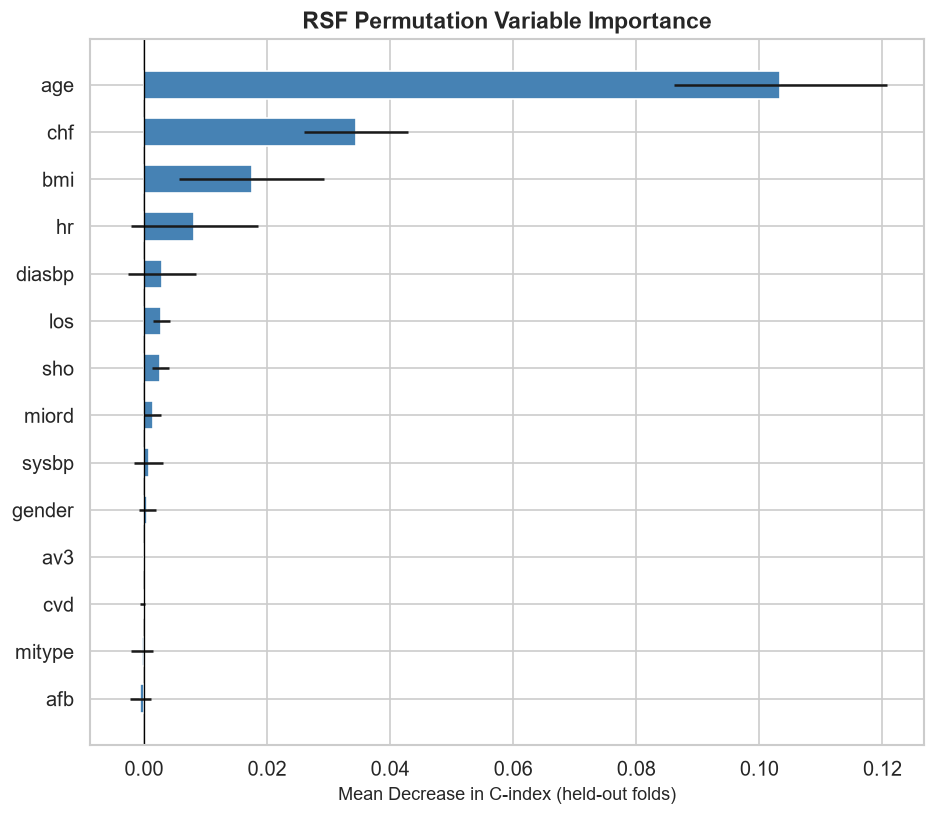

Top 5 features by permutation importance:


,Feature,Importance,Std
1,age,0.1034,0.0173
4,chf,0.0344,0.0085
3,bmi,0.0175,0.0118
8,hr,0.0082,0.0103
6,diasbp,0.0030,0.0056


In [24]:
# Each fold's forest is scored and permuted on its held-out patients only, so the C-index,
# risk scores and importances all reflect generalisation rather than memorisation.
rsf_cv_scores = []
rsf_oof_risk = np.zeros(len(df))
fold_importances = []

for fold, (train_idx, test_idx) in enumerate(kf.split(df), 1):
    rsf_cv = RandomSurvivalForest(**rsf_params)
    rsf_cv.fit(X_feat.iloc[train_idx], y_surv[train_idx])

    rsf_oof_risk[test_idx] = rsf_cv.predict(X_feat.iloc[test_idx])
    rsf_cv_scores.append(rsf_cv.score(X_feat.iloc[test_idx], y_surv[test_idx]))

    pi = permutation_importance(rsf_cv, X_feat.iloc[test_idx], y_surv[test_idx],
                                n_repeats=15, random_state=42, n_jobs=-1)
    fold_importances.append(pi.importances_mean)

fold_importances = np.array(fold_importances)
imp_df = pd.DataFrame({
    'Feature': features,
    'Importance': fold_importances.mean(axis=0),
    'Std': fold_importances.std(axis=0)
}).sort_values('Importance', ascending=True)

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(imp_df['Feature'], imp_df['Importance'],
        xerr=imp_df['Std'], color='steelblue', edgecolor='white', height=0.6)
ax.axvline(0, color='black', lw=0.8)
ax.set_xlabel('Mean Decrease in C-index (held-out folds)')
ax.set_title('RSF Permutation Variable Importance', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("Top 5 features by permutation importance:")
display(imp_df.sort_values('Importance', ascending=False).head(5).round(4))

### 6.3 Survival Curves by Risk Group (Out-of-Fold Predictions)

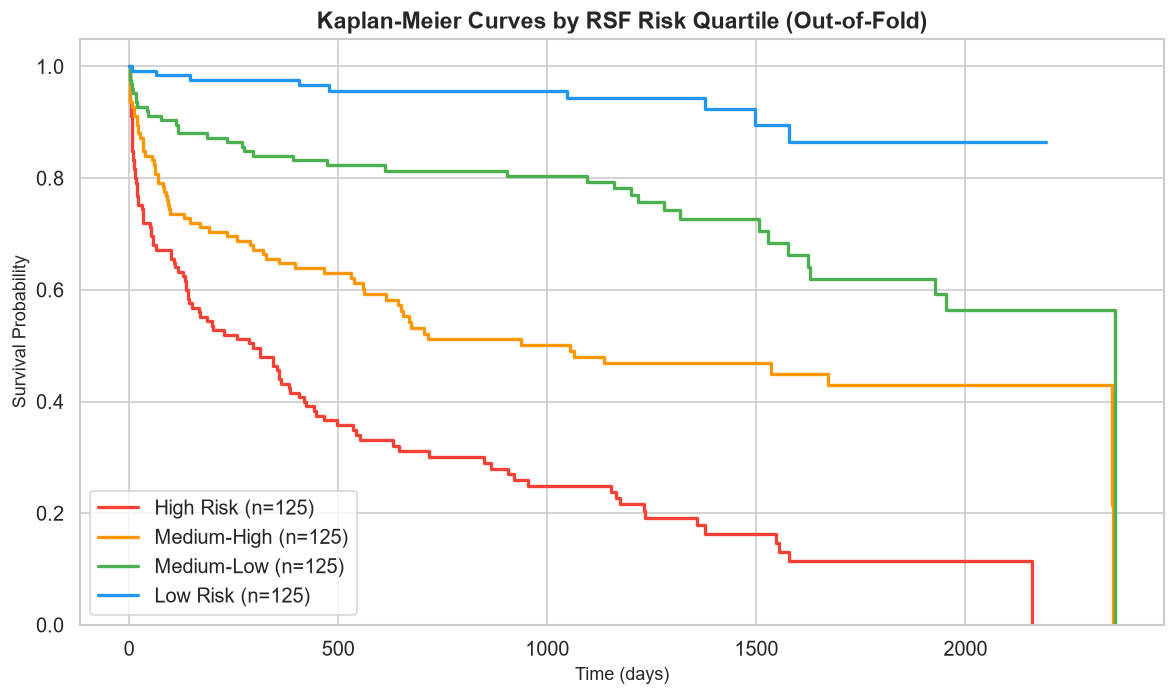

Log-rank test across RSF risk groups: p = 2.19e-38


In [25]:
df['rsf_risk_group'] = pd.qcut(rsf_oof_risk, q=4,
                                labels=['Low Risk', 'Medium-Low', 'Medium-High', 'High Risk'])

fig, ax = plt.subplots(figsize=(10, 6))
risk_colors = ['#F44336', '#FF9800', '#4CAF50', '#2196F3']

for i, grp in enumerate(['High Risk', 'Medium-High', 'Medium-Low', 'Low Risk']):
    mask = df['rsf_risk_group'] == grp
    kmf_r = KaplanMeierFitter()
    kmf_r.fit(df.loc[mask, 'time'], event_observed=df.loc[mask, 'event'],
              label=f'{grp} (n={mask.sum()})')
    kmf_r.plot_survival_function(ax=ax, ci_show=False, color=risk_colors[i], lw=2)

ax.set_title('Kaplan-Meier Curves by RSF Risk Quartile (Out-of-Fold)', fontsize=14, fontweight='bold')
ax.set_xlabel('Time (days)')
ax.set_ylabel('Survival Probability')
ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.show()

mlr_risk = multivariate_logrank_test(df['time'], df['rsf_risk_group'], df['event'])
print(f"Log-rank test across RSF risk groups: p = {mlr_risk.p_value:.2e}")

df.drop(columns='rsf_risk_group', inplace=True)

### 6.4 RSF — 5-Fold Cross-Validation

In [26]:
for fold, ci in enumerate(rsf_cv_scores, 1):
    print(f"  Fold {fold}: C-index = {ci:.4f}")

print(f"\n  Mean C-index: {np.mean(rsf_cv_scores):.4f} ± {np.std(rsf_cv_scores):.4f}")

  Fold 1: C-index = 0.7420
  Fold 2: C-index = 0.7787
  Fold 3: C-index = 0.7748
  Fold 4: C-index = 0.7616
  Fold 5: C-index = 0.7904

  Mean C-index: 0.7695 ± 0.0165


## 7. Model Comparison

We compare all three modeling approaches on **Concordance Index** (C-index):
a measure of discrimination ranging from 0.5 (random) to 1.0 (perfect),
representing the probability that a model correctly ranks a random pair of patients
by their survival times.

We also compute the **Integrated Brier Score (IBS)**: a calibration metric
that measures the mean squared error of predicted survival probabilities
across time, weighted by the IPCW censoring distribution. Every model's IBS is computed
from its **own predicted survival curves on held-out folds**, and a covariate-free
Kaplan-Meier curve is included as a reference: a useful model must beat it.

### 7.1 Cross-Validated C-Index Comparison

,Model,Mean C-index,Std C-index
2,Random Survival Forest,0.7695,0.0165
1,Weibull AFT,0.7643,0.0385
0,Cox PH (stratified),0.7584,0.0373


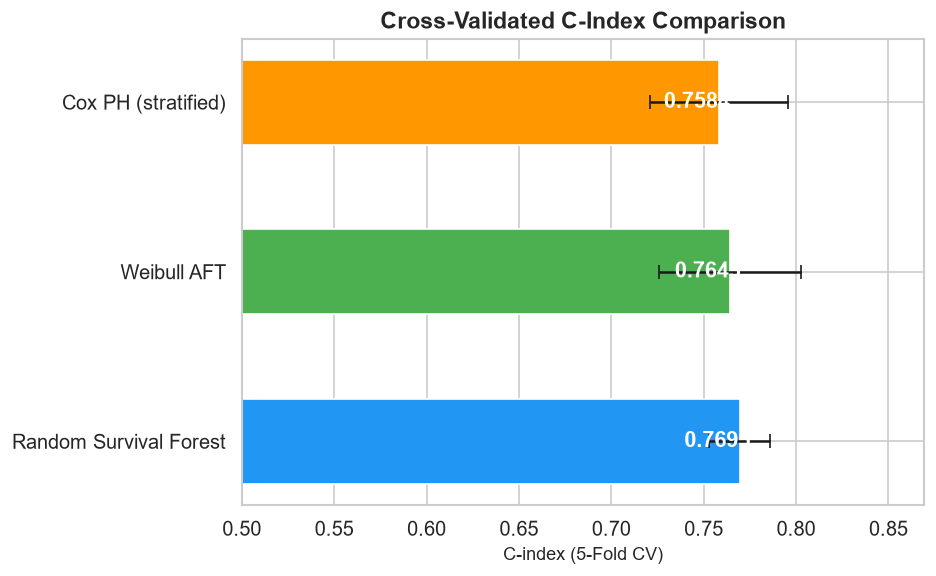

In [27]:
comparison = pd.DataFrame({
    'Model': [cox_name, f'{best_aft_name} AFT', 'Random Survival Forest'],
    'Mean C-index': [np.mean(cox_cv_scores), np.mean(aft_cv_scores), np.mean(rsf_cv_scores)],
    'Std C-index': [np.std(cox_cv_scores), np.std(aft_cv_scores), np.std(rsf_cv_scores)]
}).sort_values('Mean C-index', ascending=False)

display(comparison.round(4))

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(comparison['Model'], comparison['Mean C-index'],
               xerr=comparison['Std C-index'], color=['#2196F3', '#4CAF50', '#FF9800'],
               edgecolor='white', height=0.5, capsize=4)
ax.set_xlabel('C-index (5-Fold CV)')
ax.set_title('Cross-Validated C-Index Comparison', fontsize=14, fontweight='bold')
ax.set_xlim(0.5, max(comparison['Mean C-index']) + 0.1)

for bar, val in zip(bars, comparison['Mean C-index']):
    ax.text(val - 0.03, bar.get_y() + bar.get_height()/2,
            f'{val:.4f}', va='center', fontweight='bold', color='white')
plt.tight_layout()
plt.show()

### 7.2 Integrated Brier Score (IBS, 5-Fold CV)

In [28]:
event_times = df.loc[df['event'] == 1, 'time'].values
t_lo, t_hi = np.percentile(event_times, [10, 90])

ibs_scores = {'Kaplan-Meier (no covariates)': [], cox_name: [],
              f'{best_aft_name} AFT': [], 'Random Survival Forest': []}

for fold, (train_idx, test_idx) in enumerate(kf.split(df), 1):
    # The censoring distribution is estimated on the training fold, so held-out patients
    # followed beyond the last training time cannot be weighted and are excluded
    test_idx = test_idx[df['time'].values[test_idx] < df['time'].values[train_idx].max()]
    train, test = df.iloc[train_idx], df.iloc[test_idx]
    y_train, y_test = y_surv[train_idx], y_surv[test_idx]

    # The evaluation grid must lie inside the held-out fold's follow-up range
    times = np.linspace(max(t_lo, test['time'].min()), min(t_hi, test['time'].max() - 1), 50)

    km = KaplanMeierFitter().fit(train['time'], event_observed=train['event'])
    km_surv = np.tile(km.survival_function_at_times(times).values, (len(test), 1))

    cox_f = CoxPHFitter().fit(train[cox_cols], duration_col='time', event_col='event',
                              strata=strata_vars)
    # lifelines returns stratified predictions grouped by stratum, so restore patient order
    cox_surv = cox_f.predict_survival_function(test[features], times=times)[test.index].values.T

    aft_f = BestAFTClass().fit(train[cox_cols], duration_col='time', event_col='event')
    aft_surv = aft_f.predict_survival_function(test[features], times=times).values.T

    rsf_f = RandomSurvivalForest(**rsf_params).fit(X_feat.iloc[train_idx], y_train)
    rsf_surv = np.vstack([fn(times) for fn in
                          rsf_f.predict_survival_function(X_feat.iloc[test_idx])])

    for name, surv in zip(ibs_scores, [km_surv, cox_surv, aft_surv, rsf_surv]):
        ibs_scores[name].append(integrated_brier_score(y_train, y_test, surv, times))

ibs_df = pd.DataFrame({
    'Model': list(ibs_scores),
    'Mean IBS': [np.mean(v) for v in ibs_scores.values()],
    'Std IBS': [np.std(v) for v in ibs_scores.values()],
}).sort_values('Mean IBS')

print("=== Integrated Brier Score, 5-fold CV (lower is better) ===")
display(ibs_df.round(4))

=== Integrated Brier Score, 5-fold CV (lower is better) ===


,Model,Mean IBS,Std IBS
2,Weibull AFT,0.1537,0.0101
1,Cox PH (stratified),0.1539,0.0112
3,Random Survival Forest,0.1557,0.0035
0,Kaplan-Meier (no covariates),0.2105,0.0122


### 7.3 Summary Table

In [29]:
ibs_lookup = ibs_df.set_index('Model')['Mean IBS']
in_sample = {cox_name: strat_ci, f'{best_aft_name} AFT': best_aft.concordance_index_,
             'Random Survival Forest': rsf_ci}

print("=" * 80)
print(f"{'Model':<25} {'CV C-index':>18} {'In-sample C':>13} {'CV IBS':>10}")
print("=" * 80)
for _, row in comparison.iterrows():
    m = row['Model']
    print(f"{m:<25} {row['Mean C-index']:>9.4f} ± {row['Std C-index']:.4f}"
          f" {in_sample[m]:>13.4f} {ibs_lookup[m]:>10.4f}")
print(f"{'Kaplan-Meier (reference)':<25} {'0.5000':>18} {'':>13} "
      f"{ibs_lookup['Kaplan-Meier (no covariates)']:>10.4f}")
print("=" * 80)

# A model only "wins" if its lead is larger than the fold-to-fold variability
best = comparison.iloc[0]
tied = comparison.loc[comparison['Mean C-index'] >= best['Mean C-index'] - best['Std C-index'],
                      'Model'].tolist()
if len(tied) > 1:
    print(f"\nNo clear winner on discrimination: {', '.join(tied)} are within one fold-SD "
          f"({best['Std C-index']:.4f}) of the best mean C-index ({best['Mean C-index']:.4f}).")
else:
    print(f"\nBest performing model (CV): {best['Model']} with C-index = {best['Mean C-index']:.4f}")
print("In-sample C-indices are optimistic (especially for the RSF) and are shown for reference only.")

Model                             CV C-index   In-sample C     CV IBS
Random Survival Forest       0.7695 ± 0.0165        0.8326     0.1557
Weibull AFT                  0.7643 ± 0.0385        0.7846     0.1537
Cox PH (stratified)          0.7584 ± 0.0373        0.7827     0.1539
Kaplan-Meier (reference)              0.5000                   0.2105

No clear winner on discrimination: Random Survival Forest, Weibull AFT, Cox PH (stratified) are within one fold-SD (0.0165) of the best mean C-index (0.7695).
In-sample C-indices are optimistic (especially for the RSF) and are shown for reference only.


## 8. Conclusions

### Key Findings

1. **Dataset Profile:** WHAS500 contains 500 heart attack patients with 43% mortality over follow-up
   periods ranging from 1 to 2,358 days (median KM survival 1,627 days; 5-year survival ≈ 49%).
   A handful of implausible values (e.g. diastolic BP < 20 mmHg, n = 2) were retained; excluding
   them changes no hazard ratio by more than 1.4%.

2. **Kaplan-Meier Analysis** revealed significant survival differences by age group,
   congestive heart failure (CHF), cardiogenic shock, and atrial fibrillation status (log-rank p < 0.001).

3. **Cox Proportional Hazards:** the unstratified model violated the PH assumption for `sho`, `los`
   and `mitype`. Stratifying on `sho` and `mitype` removed every violation (all Schoenfeld p > 0.25).
   In the stratified model, older **age** (HR 1.05 per year), **CHF** (HR 2.07), higher **heart rate**
   (HR 1.01 per bpm), lower **BMI** (HR 0.96 per unit) and lower **diastolic BP** increase mortality
   risk. Female sex is associated with *lower* adjusted hazard (HR 0.74, p = 0.04), the reverse of the
   unadjusted result, because women in this cohort are older on average.

4. **Accelerated Failure Time:** the Weibull distribution fit best by both AIC (3311.6) and BIC (3379.1).
   CHF shortens expected survival time by ~73% (time ratio 0.27) and cardiogenic shock by ~90% (time ratio 0.10).

5. **Random Survival Forest** (log-rank splitting, all 500 patients) ranked **age** and **CHF** as the
   most important predictors on held-out data, followed by BMI and heart rate. Out-of-fold risk
   quartiles separate survival sharply (log-rank p ≈ 2e-38).

6. **Model Comparison:** all three models discriminate similarly in 5-fold CV
   (C-index 0.758–0.770, differences well within fold-to-fold variability) and are equally well
   calibrated (IBS 0.154–0.156, versus 0.211 for a covariate-free Kaplan-Meier curve).
   **No model is clearly superior**; the RSF's in-sample C-index (0.83) shows how optimistic
   unvalidated results would be.

### Clinical Implications

- **Age** and **CHF** are the dominant predictors of post-MI mortality across every modeling approach.
- **Cardiogenic shock** carries the largest per-patient effect in the KM, Cox and AFT analyses, but it is
  rare (4.4% of patients), so it contributes little to the RSF's population-level permutation importance.
- Since the interpretable models (Cox, Weibull AFT) perform as well as the RSF, they are preferable
  for clinical communication of risk.

---
*Analysis performed using lifelines, scikit-survival and scikit-learn in Python.*